# Notebook 3: Exploratory Data Analysis and Visualization

## Project
Exploratory Data Analysis of NIFTY 50 Futures and Options Market

## 1. Introduction

This notebook performs Exploratory Data Analysis (EDA) on the cleaned NIFTY 50 Futures and Options datasets obtained from the National Stock Exchange of India (NSE).

Building upon the data understanding and preprocessing stages completed in the previous notebooks, this stage focuses on examining historical market behaviour through statistical summaries, analytical techniques, and visualizations.

The analysis is performed on three datasets:

1. NIFTY 50 Futures
2. NIFTY 50 Call Options (CE)
3. NIFTY 50 Put Options (PE)

### Study Period

1 January 2021 to 25 September 2026.

September 2026 represents partial-month coverage and must be considered when interpreting monthly results.

## 2. Objectives

- Examine the statistical characteristics of the processed datasets.
- Analyse historical trading activity and market trends.
- Study Futures price behaviour.
- Investigate Call and Put option characteristics.
- Examine volume and Open Interest patterns.
- Analyse strike prices and expiry-related behaviour.
- Identify meaningful trends and relationships through visualizations.
- Develop data-driven observations about the NIFTY 50 derivatives market.

In [1]:
# ============================================
# 3. LIBRARY IMPORTS AND CONFIGURATION
# ============================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from scipy import stats
import statsmodels.api as sm

from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

# Visualization configuration
sns.set_theme(
    style="whitegrid",
    context="notebook"
)

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# ============================================
# 4. LOAD PROCESSED DATASETS
# ============================================

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data" / "processed").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

futures_path = PROCESSED_DATA_DIR / "futures_clean.parquet"
calls_path = PROCESSED_DATA_DIR / "calls_clean.parquet"
puts_path = PROCESSED_DATA_DIR / "puts_clean.parquet"

futures_df = pd.read_parquet(futures_path)
calls_df = pd.read_parquet(calls_path)
puts_df = pd.read_parquet(puts_path)

print("All processed datasets loaded successfully!")

All processed datasets loaded successfully!


In [3]:
# ============================================
# 5. DATASET OVERVIEW
# ============================================

datasets = {
    "Futures": futures_df,
    "Call Options (CE)": calls_df,
    "Put Options (PE)": puts_df
}

overview = []

for name, df in datasets.items():

    overview.append({
        "Dataset": name,
        "Records": len(df),
        "Columns": len(df.columns),
        "Memory Usage (MB)": (
            df.memory_usage(deep=True).sum() / (1024 ** 2)
        )
    })

overview_df = pd.DataFrame(overview)

display(overview_df)

,Dataset,Records,Columns,Memory Usage (MB)
0,Futures,4294,15,0.74
1,Call Options (CE),1261810,18,256.31
2,Put Options (PE),1300689,18,264.21


In [4]:
# ============================================
# 5.1 VERIFY DATASET DATE RANGES
# ============================================

for name, df in datasets.items():

    print(f"\n{name}")
    print("=" * 50)

    for column in ["Date", "Expiry"]:

        if column in df.columns:

            print(
                f"{column}: "
                f"{df[column].min()} to {df[column].max()}"
            )


Futures
Date: 2021-01-01 00:00:00 to 2026-09-25 00:00:00
Expiry: 2021-01-28 00:00:00 to 2026-11-23 00:00:00

Call Options (CE)
Date: 2021-01-01 00:00:00 to 2026-09-25 00:00:00
Expiry: 2021-01-07 00:00:00 to 2031-06-24 00:00:00

Put Options (PE)
Date: 2021-01-01 00:00:00 to 2026-09-25 00:00:00
Expiry: 2021-01-07 00:00:00 to 2031-06-24 00:00:00


## 6. Descriptive Statistical Analysis

Descriptive statistics provide a numerical summary of the characteristics of a dataset.

This section examines the central tendency, dispersion, and distribution of important financial variables across the Futures, Call Options, and Put Options datasets.

The analysis includes measures such as mean, median, standard deviation, minimum, maximum, and quartiles.

These statistics provide an initial understanding of market prices, trading activity, and open interest before performing detailed visual and comparative analysis.

In [5]:
# ============================================
# 6.2 NUMERICAL DATA TYPE VERIFICATION
# ============================================

for name, df in datasets.items():

    print(f"\n{name}")
    print("=" * 60)

    numeric_columns = df.select_dtypes(
        include=np.number
    ).columns.tolist()

    print("Numerical columns:")
    for column in numeric_columns:
        print("-", column)

    print("\nTotal numerical columns:", len(numeric_columns))


Futures
Numerical columns:
- Open
- High
- Low
- Close
- LTP
- Settle Price
- No. of contracts
- Turnover * in ₹ Lakhs
- Open Int
- Change in OI
- Underlying Value

Total numerical columns: 11

Call Options (CE)
Numerical columns:
- Strike Price
- Open
- High
- Low
- Close
- LTP
- Settle Price
- No. of contracts
- Turnover * in ₹ Lakhs
- Premium Turnover ** in ₹ Lakhs
- Open Int
- Change in OI
- Underlying Value

Total numerical columns: 13

Put Options (PE)
Numerical columns:
- Strike Price
- Open
- High
- Low
- Close
- LTP
- Settle Price
- No. of contracts
- Turnover * in ₹ Lakhs
- Premium Turnover ** in ₹ Lakhs
- Open Int
- Change in OI
- Underlying Value

Total numerical columns: 13


### 6.3 Descriptive Statistics

This section calculates descriptive statistics for all numerical variables.

The analysis includes:

- Count: Number of available numerical observations.
- Mean: Average value.
- Standard deviation: Measures dispersion around the mean.
- Minimum: Lowest observed value.
- 25th percentile: First quartile.
- 50th percentile: Median.
- 75th percentile: Third quartile.
- Maximum: Highest observed value.

In [6]:
# ============================================
# 6.3 DESCRIPTIVE STATISTICS
# ============================================

descriptive_statistics = {}

for name, df in datasets.items():

    numerical_df = df.select_dtypes(
        include=np.number
    )

    descriptive_statistics[name] = (
        numerical_df.describe().T
    )

    print(f"\n{name} — Descriptive Statistics")
    print("=" * 70)

    display(descriptive_statistics[name])


Futures — Descriptive Statistics


,count,mean,std,min,25%,50%,75%,max
Open,"4,263.00","20,736.66","3,704.23","13,785.00","17,525.50","20,055.25","24,350.60","26,770.10"
High,"4,263.00","20,833.27","3,707.89","13,896.90","17,627.70","20,125.00","24,456.25","26,825.00"
Low,"4,263.00","20,629.80","3,697.39","13,666.60","17,424.00","19,990.10","24,225.05","26,671.20"
Close,"4,263.00","20,735.38","3,698.81","13,709.10","17,540.62","20,066.70","24,349.43","26,772.60"
LTP,"4,263.00","20,737.00","3,698.60","13,717.25","17,545.38","20,068.75","24,349.90","26,795.00"
Settle Price,"4,263.00","20,735.43","3,698.83","13,709.10","17,540.62","20,066.70","24,349.43","26,772.60"
No. of contracts,"4,263.00","63,049.18","88,695.89",260.00,"4,580.50","14,257.00","105,373.00","1,615,661.00"
Turnover * in ₹ Lakhs,"4,263.00","618,416.86","757,154.90","2,344.29","49,707.99","146,448.17","1,185,848.25","9,000,933.66"
Open Int,"4,263.00","4,978,355.12","5,451,721.01","15,300.00","555,800.00","1,675,400.00","10,213,687.50","21,563,945.00"
Change in OI,"4,262.00","66,709.91","876,657.71","-4,581,000.00","-1,725.00","38,037.50","139,875.00","6,602,830.00"



Call Options (CE) — Descriptive Statistics


,count,mean,std,min,25%,50%,75%,max
Strike Price,"1,261,810.00","20,065.91","4,317.22","6,000.00","16,600.00","19,500.00","23,700.00","41,000.00"
Open,"578,243.00",607.13,954.30,0.05,17.00,229.10,813.65,"12,035.35"
High,"578,243.00",636.68,966.69,0.05,20.30,265.65,870.45,"12,035.35"
Low,"578,243.00",575.49,942.91,0.05,11.20,187.30,757.27,"12,035.35"
Close,"1,245,025.00","1,341.41","1,758.06",0.05,162.65,791.90,"1,729.65","14,862.95"
LTP,"719,244.00",897.26,"1,314.44",0.05,27.39,379.00,"1,275.00","12,035.35"
Settle Price,"1,244,204.00","1,929.17","3,534.98",0.01,144.00,856.55,"2,060.50","26,216.05"
No. of contracts,"578,146.00","126,965.20","1,190,901.33",1.00,29.00,384.00,"5,838.00","80,941,909.00"
Turnover * in ₹ Lakhs,"578,243.00","1,484,330.51","13,910,474.54",5.48,326.54,"4,454.07","67,597.21","849,066,374.18"
Premium Turnover ** in ₹ Lakhs,"577,175.00","2,912.50","22,071.34",0.01,2.75,24.39,233.91,"1,011,173.28"



Put Options (PE) — Descriptive Statistics


,count,mean,std,min,25%,50%,75%,max
Strike Price,"1,300,689.00","19,813.70","4,490.42","6,000.00","16,350.00","19,250.00","23,600.00","41,000.00"
Open,"603,757.00",410.50,646.90,0.05,17.60,139.95,533.50,"11,250.00"
High,"603,757.00",440.62,665.32,0.05,21.15,165.75,595.00,"11,250.00"
Low,"603,757.00",382.89,631.58,0.05,12.35,113.70,479.85,"11,250.00"
Close,"1,284,126.00",810.59,"1,090.28",0.05,60.80,371.10,"1,214.25","11,250.00"
LTP,"782,427.00",485.19,725.53,0.05,21.00,167.20,677.65,"11,250.00"
Settle Price,"1,270,630.00","1,165.67","3,189.04",0.01,42.45,346.80,"1,179.95","26,216.05"
No. of contracts,"603,653.00","115,817.15","1,130,731.42",1.00,36.00,485.00,"6,402.00","95,341,669.00"
Turnover * in ₹ Lakhs,"603,757.00","1,328,966.26","13,349,799.86",3.01,399.29,"5,302.88","67,621.81","874,519,118.02"
Premium Turnover ** in ₹ Lakhs,"601,467.00","2,743.57","21,207.77",0.01,2.42,23.38,228.20,"963,032.24"


In [7]:
# ============================================
# 6.4 MEAN AND MEDIAN ANALYSIS
# ============================================

central_tendency = []

for name, df in datasets.items():

    numerical_df = df.select_dtypes(
        include=np.number
    )

    for column in numerical_df.columns:

        central_tendency.append({
            "Dataset": name,
            "Variable": column,
            "Mean": numerical_df[column].mean(),
            "Median": numerical_df[column].median()
        })


central_tendency_df = pd.DataFrame(
    central_tendency
)

display(central_tendency_df)

,Dataset,Variable,Mean,Median
0,Futures,Open,"20,736.66","20,055.25"
1,Futures,High,"20,833.27","20,125.00"
2,Futures,Low,"20,629.80","19,990.10"
3,Futures,Close,"20,735.38","20,066.70"
4,Futures,LTP,"20,737.00","20,068.75"
5,Futures,Settle Price,"20,735.43","20,066.70"
6,Futures,No. of contracts,"63,049.18","14,257.00"
7,Futures,Turnover * in ₹ Lakhs,"618,416.86","146,448.17"
8,Futures,Open Int,"4,978,355.12","1,675,400.00"
9,Futures,Change in OI,"66,709.91","38,037.50"


In [8]:
# ============================================
# 6.5 STANDARD DEVIATION ANALYSIS
# ============================================

dispersion_results = []

for name, df in datasets.items():

    numerical_df = df.select_dtypes(
        include=np.number
    )

    for column in numerical_df.columns:

        dispersion_results.append({
            "Dataset": name,
            "Variable": column,
            "Standard Deviation": numerical_df[column].std(),
            "Variance": numerical_df[column].var()
        })


dispersion_df = pd.DataFrame(
    dispersion_results
)

display(dispersion_df)

,Dataset,Variable,Standard Deviation,Variance
0,Futures,Open,"3,704.23","13,721,328.02"
1,Futures,High,"3,707.89","13,748,430.90"
2,Futures,Low,"3,697.39","13,670,725.42"
3,Futures,Close,"3,698.81","13,681,162.89"
4,Futures,LTP,"3,698.60","13,679,606.92"
5,Futures,Settle Price,"3,698.83","13,681,321.85"
6,Futures,No. of contracts,"88,695.89","7,866,960,512.04"
7,Futures,Turnover * in ₹ Lakhs,"757,154.90","573,283,544,052.04"
8,Futures,Open Int,"5,451,721.01","29,721,261,930,290.82"
9,Futures,Change in OI,"876,657.71","768,528,746,411.41"


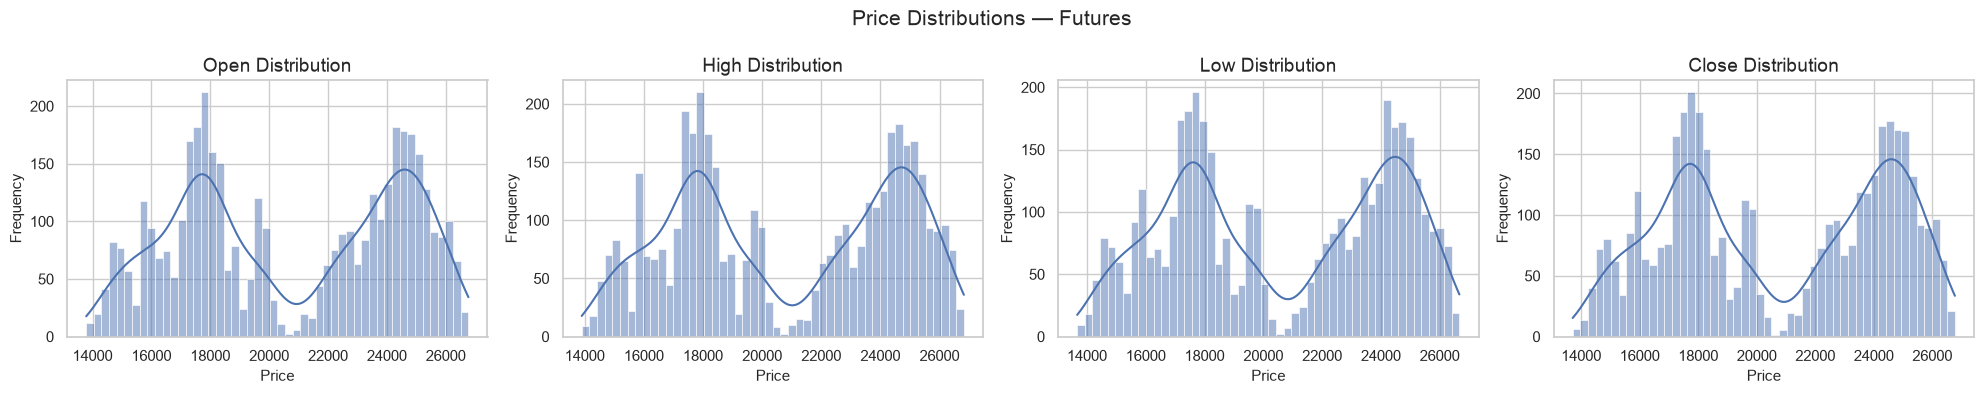

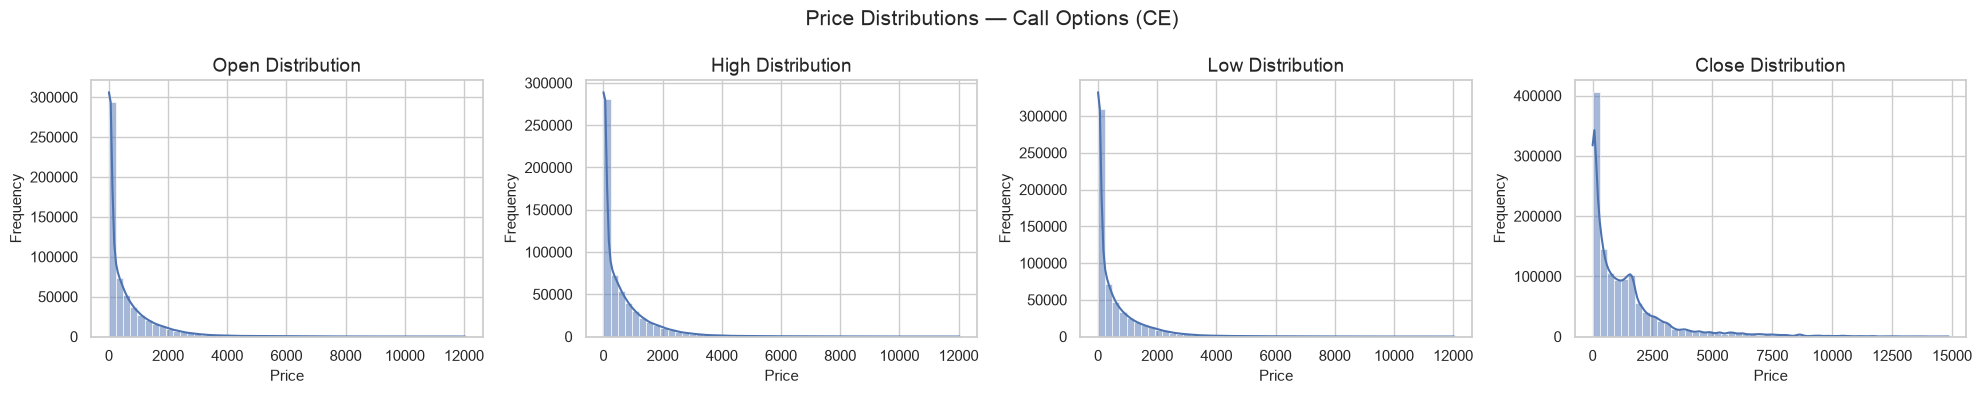

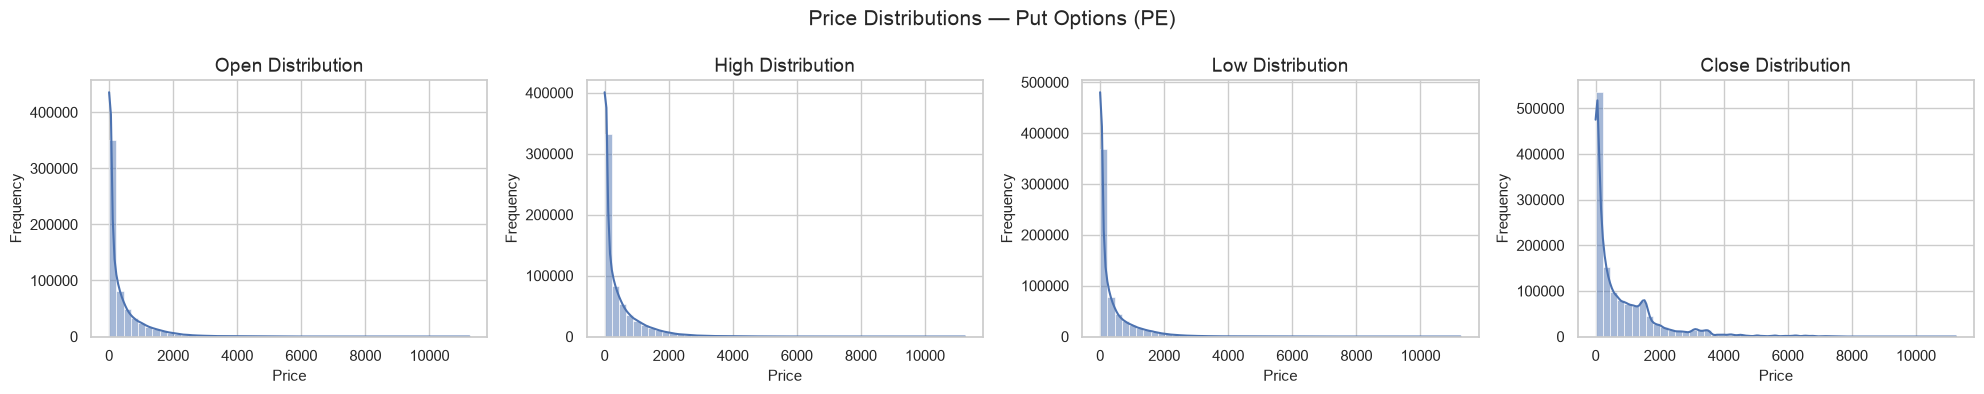

In [9]:
# ============================================
# 6.6 PRICE DISTRIBUTION ANALYSIS
# ============================================

price_columns = [
    "Open",
    "High",
    "Low",
    "Close"
]

for name, df in datasets.items():

    available_columns = [
        col for col in price_columns
        if col in df.columns
    ]

    if not available_columns:
        print(f"No OHLC columns available for {name}")
        continue

    fig, axes = plt.subplots(
        1,
        len(available_columns),
        figsize=(5 * len(available_columns), 4)
    )

    if len(available_columns) == 1:
        axes = [axes]

    for ax, column in zip(axes, available_columns):

        sns.histplot(
            df[column].dropna(),
            bins=50,
            kde=True,
            ax=ax
        )

        ax.set_title(f"{column} Distribution")
        ax.set_xlabel("Price")
        ax.set_ylabel("Frequency")

    fig.suptitle(
        f"Price Distributions — {name}",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()

## 7. Trading Activity Analysis

Trading activity provides insights into the participation and activity levels of the derivatives market.

This section examines historical trading activity across Futures, Call Options (CE), and Put Options (PE).

The analysis focuses on the number of contracts traded and their distribution over daily, monthly, and yearly periods.

The objective is to identify periods of increased or decreased market activity and examine differences between the three instrument categories.

September 2026 represents partial-month coverage and is considered separately when interpreting monthly results.

In [10]:
# ============================================
# 7.2 TRADING VOLUME COLUMN VERIFICATION
# ============================================

for name, df in datasets.items():

    print(f"\n{name}")
    print("=" * 50)

    if "No. of contracts" in df.columns:

        print("Trading volume column found.")
        print("Data type:", df["No. of contracts"].dtype)
        print("Total contracts traded:",
              f"{df['No. of contracts'].sum():,.0f}")

    else:
        print("Trading volume column not found.")


Futures
Trading volume column found.
Data type: float64
Total contracts traded: 268,778,637

Call Options (CE)
Trading volume column found.
Data type: float64
Total contracts traded: 73,404,424,377

Put Options (PE)
Trading volume column found.
Data type: float64
Total contracts traded: 69,913,372,822


In [11]:
# ============================================
# 7.3 DAILY TRADING ACTIVITY
# ============================================

daily_activity = {}

for name, df in datasets.items():

    daily = (
        df.groupby("Date")["No. of contracts"]
        .sum()
        .reset_index()
        .sort_values("Date")
    )

    daily_activity[name] = daily

    print(f"\n{name}")
    display(daily.head())


Futures


,Date,No. of contracts
0,2021-01-01,"64,130.00"
1,2021-01-04,"139,548.00"
2,2021-01-05,"135,453.00"
3,2021-01-06,"162,142.00"
4,2021-01-07,"103,900.00"



Call Options (CE)


,Date,No. of contracts
0,2021-01-01,"1,831,539.00"
1,2021-01-04,"4,654,570.00"
2,2021-01-05,"5,324,933.00"
3,2021-01-06,"7,547,789.00"
4,2021-01-07,"9,764,517.00"



Put Options (PE)


,Date,No. of contracts
0,2021-01-01,"1,980,273.00"
1,2021-01-04,"4,866,202.00"
2,2021-01-05,"5,120,351.00"
3,2021-01-06,"8,145,315.00"
4,2021-01-07,"10,427,242.00"


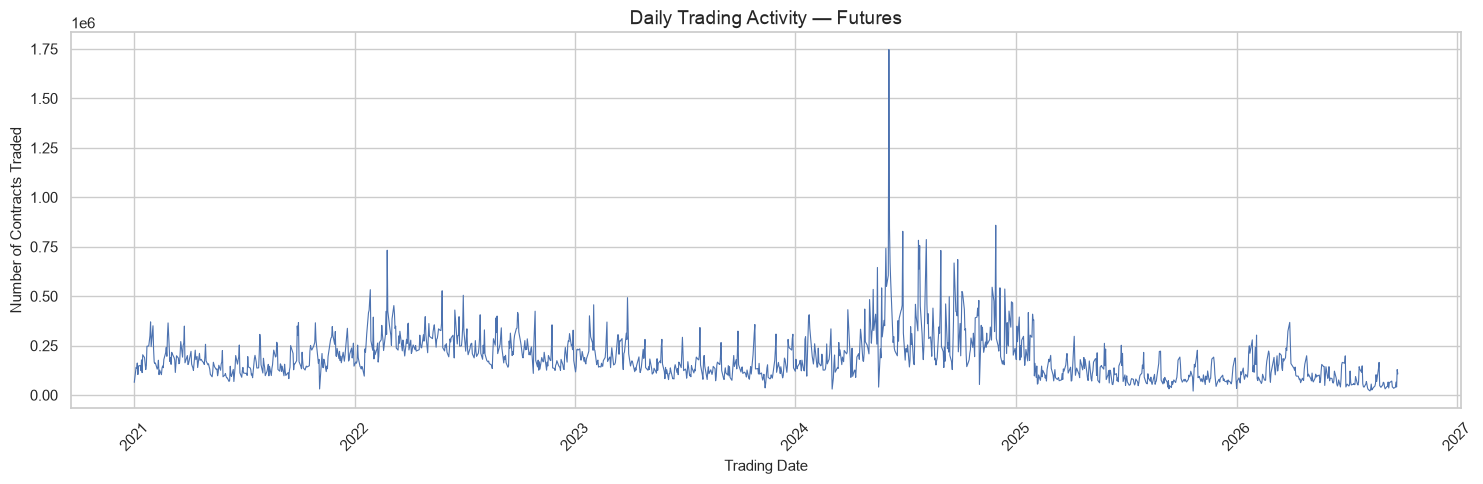

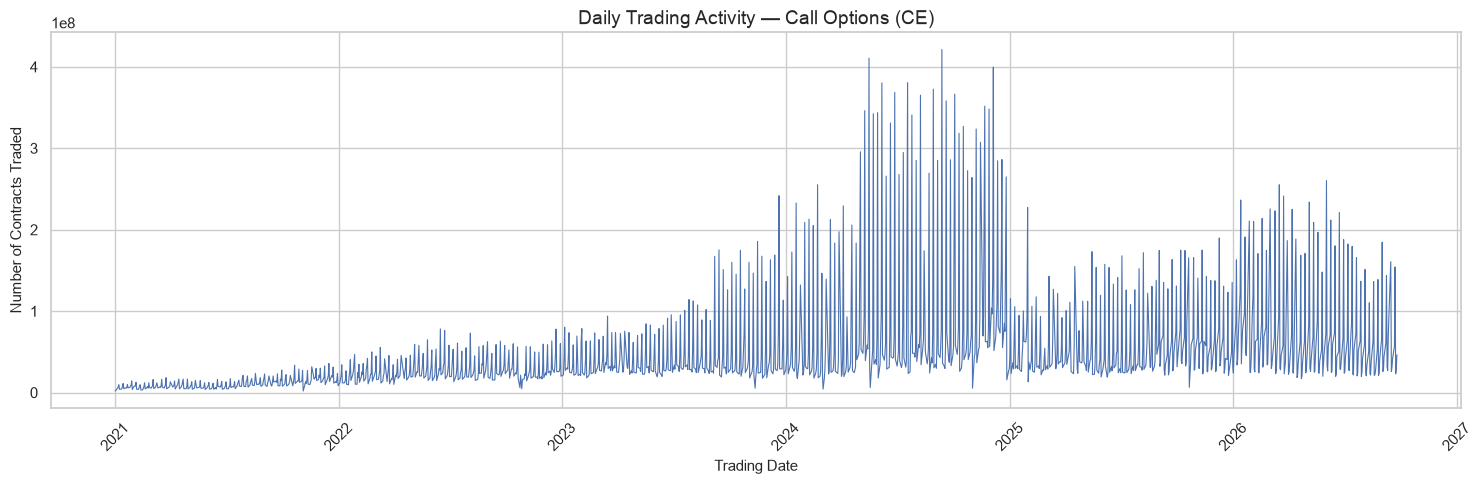

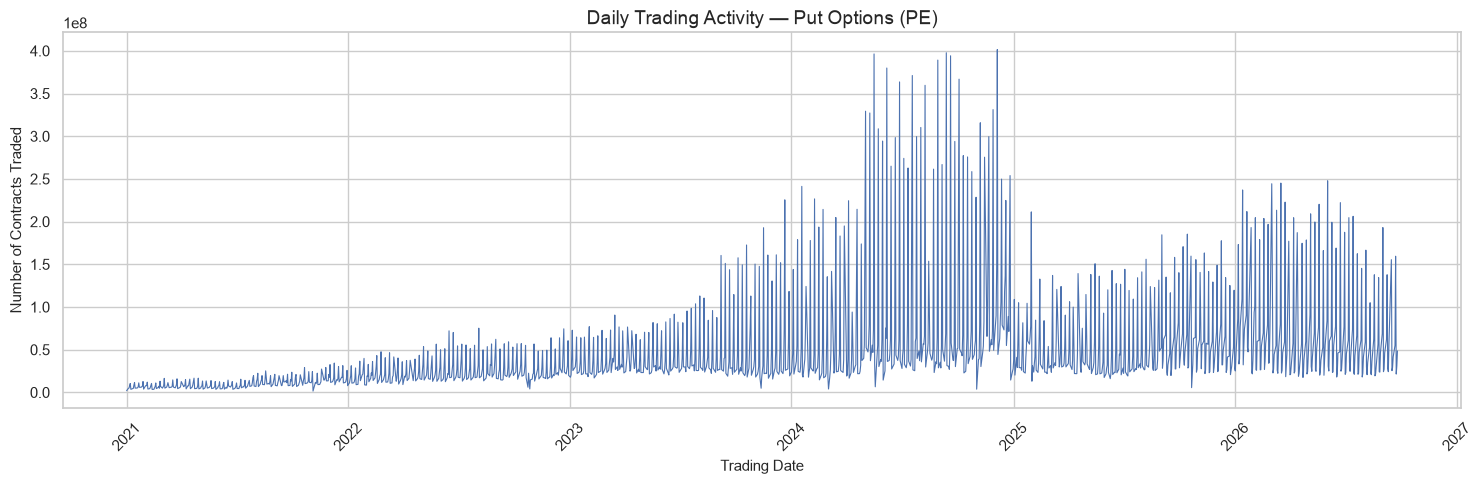

In [12]:
# ============================================
# 7.4 DAILY TRADING ACTIVITY VISUALIZATION
# ============================================

for name, daily in daily_activity.items():

    plt.figure(figsize=(15, 5))

    plt.plot(
        daily["Date"],
        daily["No. of contracts"],
        linewidth=0.8
    )

    plt.title(f"Daily Trading Activity — {name}")
    plt.xlabel("Trading Date")
    plt.ylabel("Number of Contracts Traded")

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### 7.5 Monthly Trading Activity

Daily trading activity may fluctuate significantly. Therefore, the observations are aggregated by month to examine broader trends in derivatives market participation.

Monthly contract volume is calculated by summing the number of contracts traded during each calendar month.

In [13]:
# ============================================
# 7.5 MONTHLY TRADING ACTIVITY
# ============================================

monthly_activity = {}

for name, df in datasets.items():

    monthly = (
        df.groupby(df["Date"].dt.to_period("M"))
        ["No. of contracts"]
        .sum()
        .reset_index()
    )

    monthly["Date"] = monthly["Date"].dt.to_timestamp()

    monthly_activity[name] = monthly

    print(f"\n{name} — Monthly Activity")
    display(monthly.head())


Futures — Monthly Activity


,Date,No. of contracts
0,2021-01-01,"3,556,745.00"
1,2021-02-01,"3,770,050.00"
2,2021-03-01,"4,179,946.00"
3,2021-04-01,"3,372,804.00"
4,2021-05-01,"2,703,365.00"



Call Options (CE) — Monthly Activity


,Date,No. of contracts
0,2021-01-01,"133,053,871.00"
1,2021-02-01,"141,962,259.00"
2,2021-03-01,"178,559,787.00"
3,2021-04-01,"170,697,158.00"
4,2021-05-01,"155,599,489.00"



Put Options (PE) — Monthly Activity


,Date,No. of contracts
0,2021-01-01,"132,355,955.00"
1,2021-02-01,"141,074,206.00"
2,2021-03-01,"166,856,003.00"
3,2021-04-01,"163,925,891.00"
4,2021-05-01,"145,574,471.00"


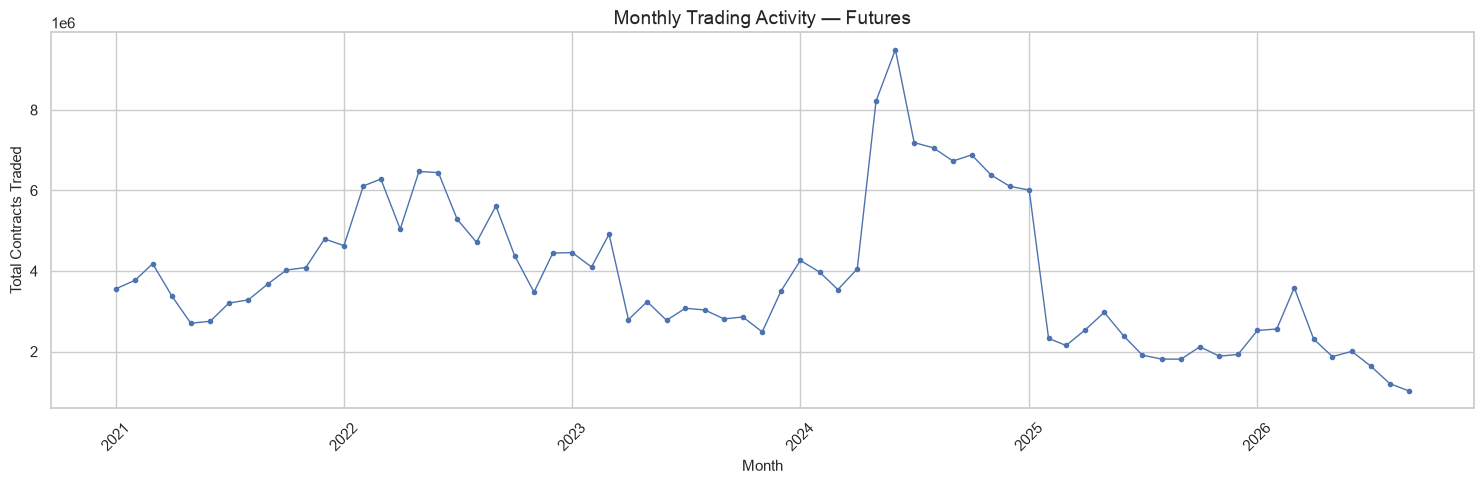

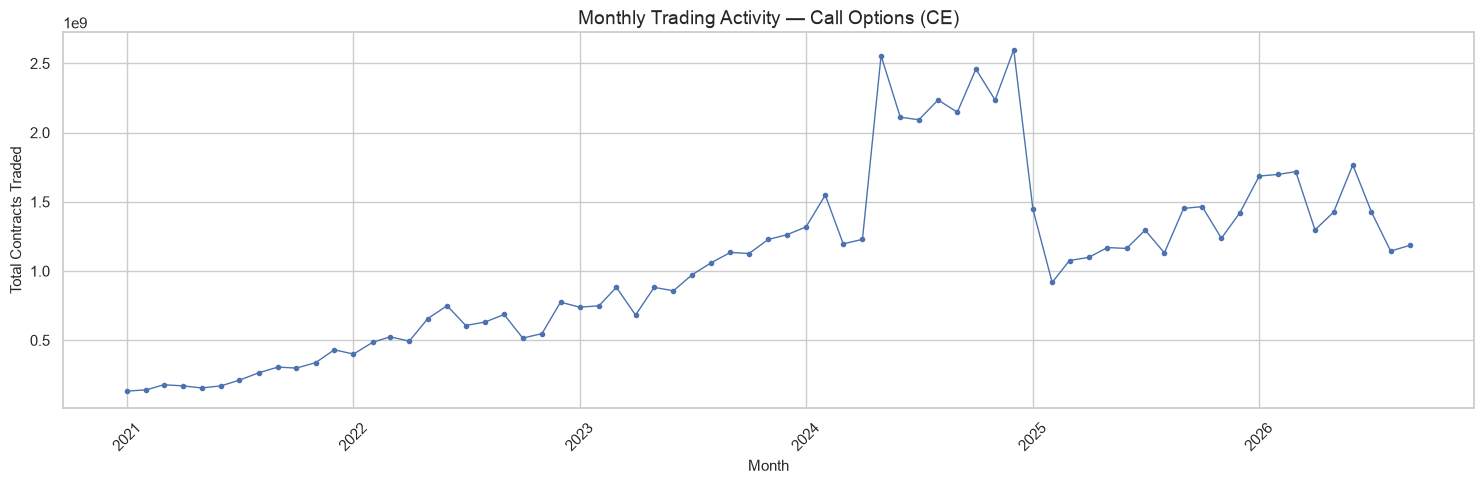

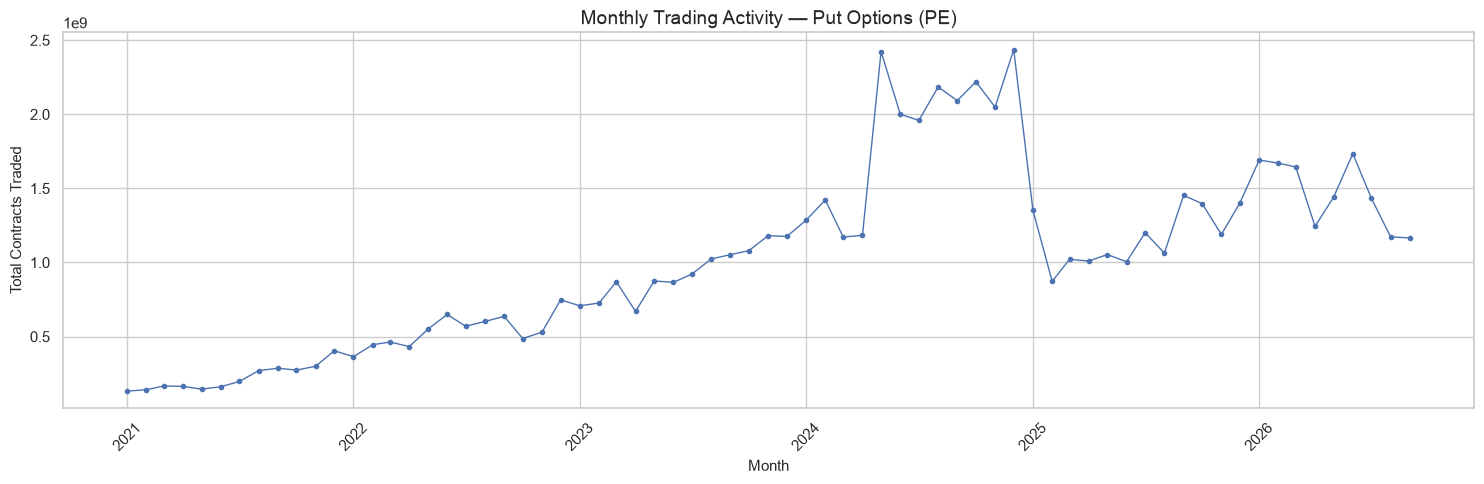

In [14]:
# ============================================
# 7.6 MONTHLY TRADING ACTIVITY VISUALIZATION
# ============================================

for name, monthly in monthly_activity.items():

    plt.figure(figsize=(15, 5))

    plt.plot(
        monthly["Date"],
        monthly["No. of contracts"],
        marker="o",
        markersize=3,
        linewidth=1
    )

    plt.title(f"Monthly Trading Activity — {name}")
    plt.xlabel("Month")
    plt.ylabel("Total Contracts Traded")

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [15]:
# ============================================
# 7.7 YEARLY TRADING ACTIVITY
# ============================================

yearly_activity = {}

for name, df in datasets.items():

    yearly = (
        df.groupby(df["Date"].dt.year)
        ["No. of contracts"]
        .sum()
        .reset_index()
    )

    yearly.columns = [
        "Year",
        "Total Contracts Traded"
    ]

    yearly_activity[name] = yearly

    print(f"\n{name} — Yearly Activity")
    display(yearly)


Futures — Yearly Activity


,Year,Total Contracts Traded
0,2021,"43,398,575.00"
1,2022,"62,889,450.00"
2,2023,"40,039,536.00"
3,2024,"73,882,452.00"
4,2025,"29,854,788.00"
5,2026,"18,713,836.00"



Call Options (CE) — Yearly Activity


,Year,Total Contracts Traded
0,2021,"2,802,276,836.00"
1,2022,"7,074,321,624.00"
2,2023,"11,575,694,439.00"
3,2024,"23,728,295,044.00"
4,2025,"14,875,862,699.00"
5,2026,"13,347,973,735.00"



Put Options (PE) — Yearly Activity


,Year,Total Contracts Traded
0,2021,"2,643,790,376.00"
1,2022,"6,476,836,815.00"
2,2023,"11,150,975,594.00"
3,2024,"22,425,262,937.00"
4,2025,"14,021,322,760.00"
5,2026,"13,195,184,340.00"


In [16]:
# ============================================
# 7.8 YEARLY COMPARISON
# ============================================

yearly_comparison = []

for name, yearly in yearly_activity.items():

    yearly = yearly.copy()
    yearly["Dataset"] = name

    yearly_comparison.append(yearly)

yearly_comparison_df = pd.concat(
    yearly_comparison,
    ignore_index=True
)

fig = px.bar(
    yearly_comparison_df,
    x="Year",
    y="Total Contracts Traded",
    color="Dataset",
    barmode="group",
    title="Yearly Trading Activity Comparison"
)

fig.update_layout(
    xaxis_title="Year",
    yaxis_title="Total Contracts Traded",
    template="plotly_white"
)

fig.show()

In [17]:
# ============================================
# 7.9 TOP 10 MONTHS BY TRADING ACTIVITY
# ============================================

for name, monthly in monthly_activity.items():

    print(f"\n{name} — Top 10 Months")
    print("=" * 60)

    top_months = monthly.nlargest(
        10,
        "No. of contracts"
    )

    display(top_months)


Futures — Top 10 Months


,Date,No. of contracts
41,2024-06-01,"9,498,382.00"
40,2024-05-01,"8,216,884.00"
42,2024-07-01,"7,188,920.00"
43,2024-08-01,"7,056,304.00"
45,2024-10-01,"6,881,996.00"
44,2024-09-01,"6,730,492.00"
16,2022-05-01,"6,471,364.00"
17,2022-06-01,"6,443,429.00"
46,2024-11-01,"6,384,708.00"
14,2022-03-01,"6,282,772.00"



Call Options (CE) — Top 10 Months


,Date,No. of contracts
47,2024-12-01,"2,599,681,135.00"
40,2024-05-01,"2,556,008,451.00"
45,2024-10-01,"2,458,403,421.00"
43,2024-08-01,"2,235,893,487.00"
46,2024-11-01,"2,235,135,962.00"
44,2024-09-01,"2,147,163,668.00"
41,2024-06-01,"2,111,410,685.00"
42,2024-07-01,"2,092,506,612.00"
65,2026-06-01,"1,766,545,223.00"
62,2026-03-01,"1,717,937,332.00"



Put Options (PE) — Top 10 Months


,Date,No. of contracts
47,2024-12-01,"2,436,693,076.00"
40,2024-05-01,"2,423,019,312.00"
45,2024-10-01,"2,219,483,781.00"
43,2024-08-01,"2,184,281,451.00"
44,2024-09-01,"2,092,377,744.00"
46,2024-11-01,"2,048,570,895.00"
41,2024-06-01,"2,001,107,525.00"
42,2024-07-01,"1,958,251,836.00"
65,2026-06-01,"1,733,998,059.00"
60,2026-01-01,"1,691,485,095.00"


In [18]:
# ============================================
# 7.10 TRADING ACTIVITY SUMMARY
# ============================================

activity_summary = []

for name, daily in daily_activity.items():

    activity_summary.append({
        "Dataset": name,
        "Trading Days": daily["Date"].nunique(),
        "Total Contracts": daily["No. of contracts"].sum(),
        "Average Daily Contracts": daily["No. of contracts"].mean(),
        "Maximum Daily Contracts": daily["No. of contracts"].max(),
        "Minimum Daily Contracts": daily["No. of contracts"].min()
    })

activity_summary_df = pd.DataFrame(activity_summary)

display(
    activity_summary_df.style.format({
        "Trading Days": "{:,.0f}",
        "Total Contracts": "{:,.0f}",
        "Average Daily Contracts": "{:,.2f}",
        "Maximum Daily Contracts": "{:,.0f}",
        "Minimum Daily Contracts": "{:,.0f}"
    })
)

display(activity_summary_df)

,Dataset,Trading Days,Total Contracts,Average Daily Contracts,Maximum Daily Contracts,Minimum Daily Contracts
0,Futures,"1,421","268,778,637","189,147.53","1,746,793","20,264"
1,Call Options (CE),"1,421","73,404,424,377","51,656,878.52","421,147,400","1,831,539"
2,Put Options (PE),"1,421","69,913,372,822","49,200,121.62","401,452,352","1,531,666"


,Dataset,Trading Days,Total Contracts,Average Daily Contracts,Maximum Daily Contracts,Minimum Daily Contracts
0,Futures,1421,"268,778,637.00","189,147.53","1,746,793.00","20,264.00"
1,Call Options (CE),1421,"73,404,424,377.00","51,656,878.52","421,147,400.00","1,831,539.00"
2,Put Options (PE),1421,"69,913,372,822.00","49,200,121.62","401,452,352.00","1,531,666.00"


## 8. NIFTY 50 Futures Analysis

This section explores the behaviour of NIFTY 50 futures contracts over the
study period from January 2021 to September 2026.

The analysis focuses on:

- Futures price movements over time.
- Daily price returns.
- Open, High, Low, and Close price behaviour.
- Open Interest trends.
- Relationship between futures prices and Open Interest.

The objective is to identify major trends, fluctuations, and patterns in
the NIFTY 50 futures market.

In [19]:
# Create a separate copy for futures analysis
futures_analysis = futures_df.copy()

# Sort data by trading date
futures_analysis = futures_analysis.sort_values("Date").reset_index(drop=True)

# Display available columns
print("Available columns:")
print(futures_analysis.columns.tolist())

# Display first five records
display(futures_analysis.head())

Available columns:
['Symbol', 'Date', 'Expiry', 'Open', 'High', 'Low', 'Close', 'LTP', 'Settle Price', 'No. of contracts', 'Turnover * in ₹ Lakhs', 'Open Int', 'Change in OI', 'Underlying Value', 'source_file']


,Symbol,Date,Expiry,Open,High,Low,Close,LTP,Settle Price,No. of contracts,Turnover * in ₹ Lakhs,Open Int,Change in OI,Underlying Value,source_file
0,NIFTY,2021-01-01,2021-03-25,"14,069.00","14,127.80","14,069.00","14,111.65","14,110.05","14,111.65",763.00,"8,070.16","32,100.00","32,100.00","14,018.50",Futures/2021/FUTIDX_NIFTY_01-Jan-2021_TO_31-Ma...
1,NIFTY,2021-01-01,2021-02-25,"14,043.00","14,103.00","14,036.20","14,086.50","14,085.00","14,086.50","2,537.00","26,787.73","953,775.00","27,300.00","14,018.50",Futures/2021/FUTIDX_NIFTY_01-Jan-2021_TO_31-Ma...
2,NIFTY,2021-01-01,2021-01-28,"14,002.10","14,073.95","13,997.05","14,053.85","14,050.50","14,053.85","60,830.00","640,917.26","12,168,975.00","368,325.00","14,018.50",Futures/2021/FUTIDX_NIFTY_01-Jan-2021_TO_31-Ma...
3,NIFTY,2021-01-04,2021-03-25,"14,191.00","14,229.00","14,039.40","14,217.15","14,229.00","14,217.15",826.00,"8,775.68","50,400.00","18,300.00","14,132.90",Futures/2021/FUTIDX_NIFTY_01-Jan-2021_TO_31-Ma...
4,NIFTY,2021-01-04,2021-02-25,"14,156.55","14,210.65","14,004.90","14,197.95","14,208.65","14,197.95","4,061.00","43,071.81","982,950.00","29,175.00","14,132.90",Futures/2021/FUTIDX_NIFTY_01-Jan-2021_TO_31-Ma...


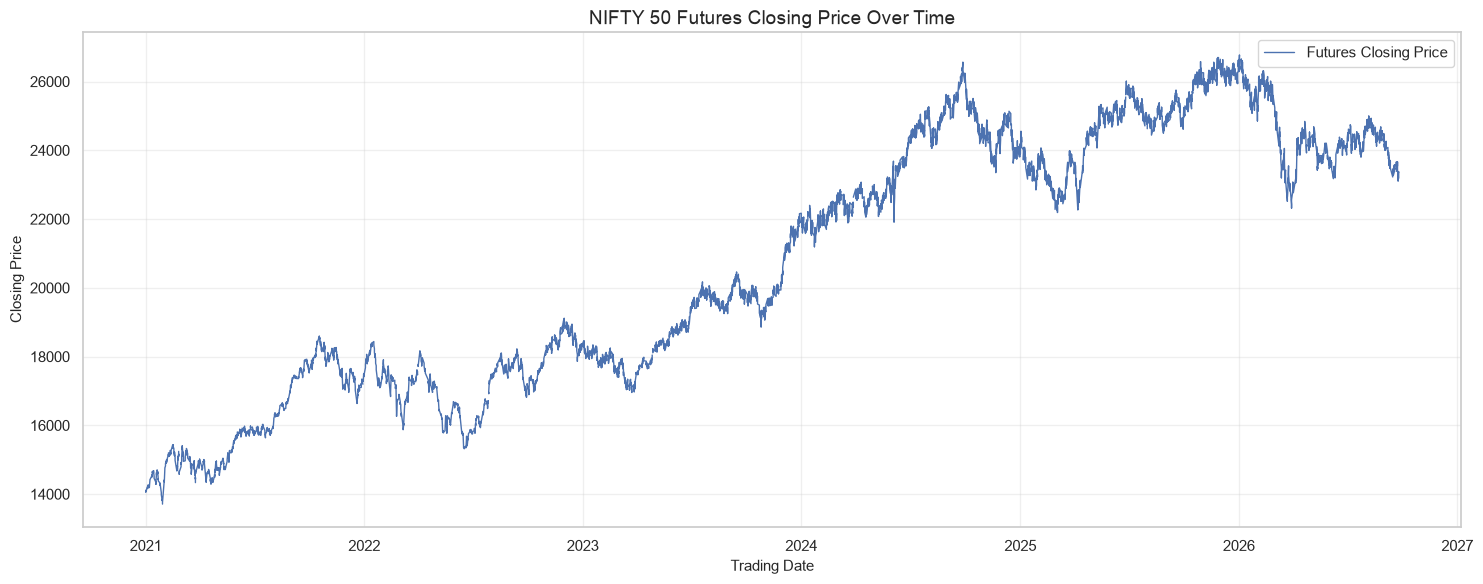

In [20]:
plt.figure(figsize=(15, 6))

plt.plot(
    futures_analysis["Date"],
    futures_analysis["Close"],
    label="Futures Closing Price",
    linewidth=1
)

plt.title("NIFTY 50 Futures Closing Price Over Time")
plt.xlabel("Trading Date")
plt.ylabel("Closing Price")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
# Calculate daily percentage returns
futures_analysis["Daily_Return"] = (
    futures_analysis["Close"].pct_change() * 100
)

display(
    futures_analysis[
        ["Date", "Close", "Daily_Return"]
    ].head(10)
)

,Date,Close,Daily_Return
0,2021-01-01,"14,111.65",NaN
1,2021-01-01,"14,086.50",-0.18
2,2021-01-01,"14,053.85",-0.23
3,2021-01-04,"14,217.15",1.16
4,2021-01-04,"14,197.95",-0.14
5,2021-01-04,"14,165.30",-0.23
6,2021-01-05,"14,251.90",0.61
7,2021-01-05,"14,217.95",-0.24
8,2021-01-05,"14,268.40",0.35
9,2021-01-06,"14,223.35",-0.32


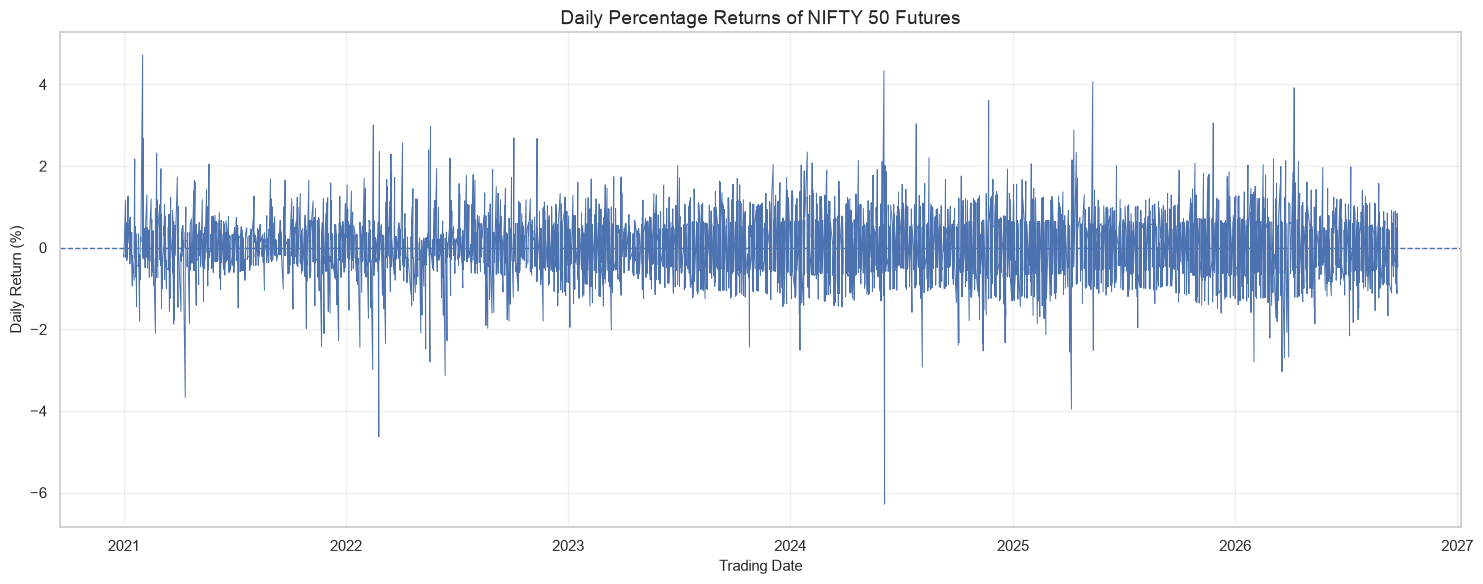

In [22]:
plt.figure(figsize=(15, 6))

plt.plot(
    futures_analysis["Date"],
    futures_analysis["Daily_Return"],
    linewidth=0.7
)

plt.axhline(y=0, linestyle="--", linewidth=1)

plt.title("Daily Percentage Returns of NIFTY 50 Futures")
plt.xlabel("Trading Date")
plt.ylabel("Daily Return (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

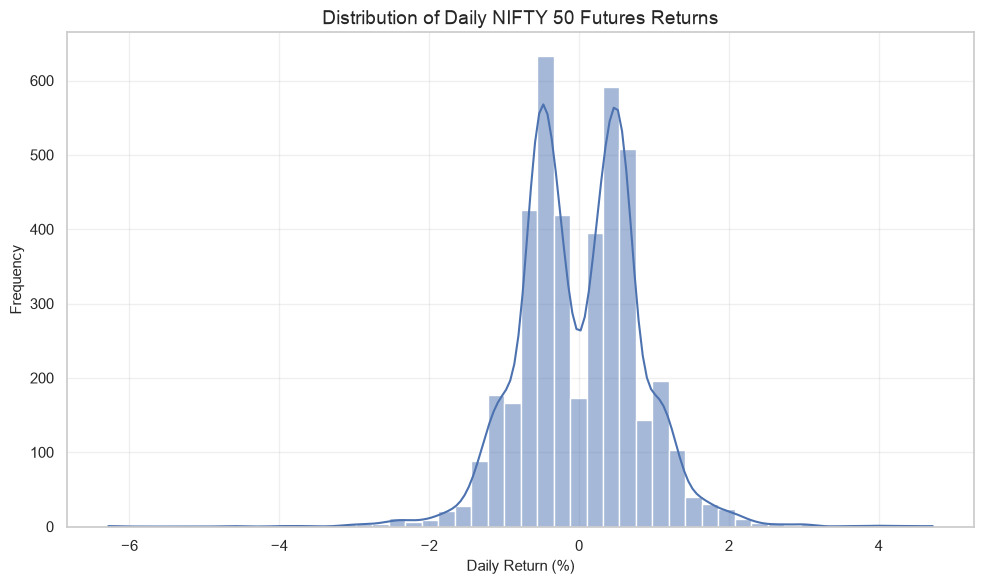

In [23]:
returns = futures_analysis["Daily_Return"].dropna()

plt.figure(figsize=(10, 6))

sns.histplot(
    returns,
    bins=50,
    kde=True
)

plt.title("Distribution of Daily NIFTY 50 Futures Returns")
plt.xlabel("Daily Return (%)")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

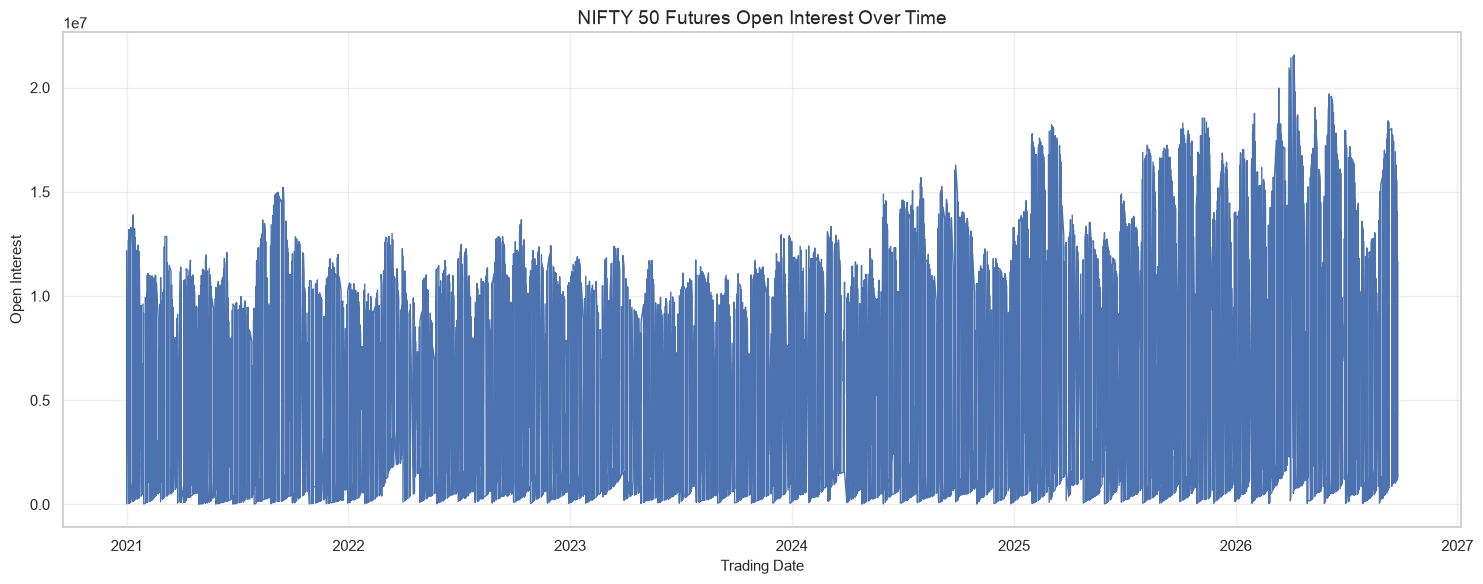

In [24]:
plt.figure(figsize=(15, 6))

plt.plot(
    futures_analysis["Date"],
    futures_analysis["Open Int"],
    linewidth=1
)

plt.title("NIFTY 50 Futures Open Interest Over Time")
plt.xlabel("Trading Date")
plt.ylabel("Open Interest")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

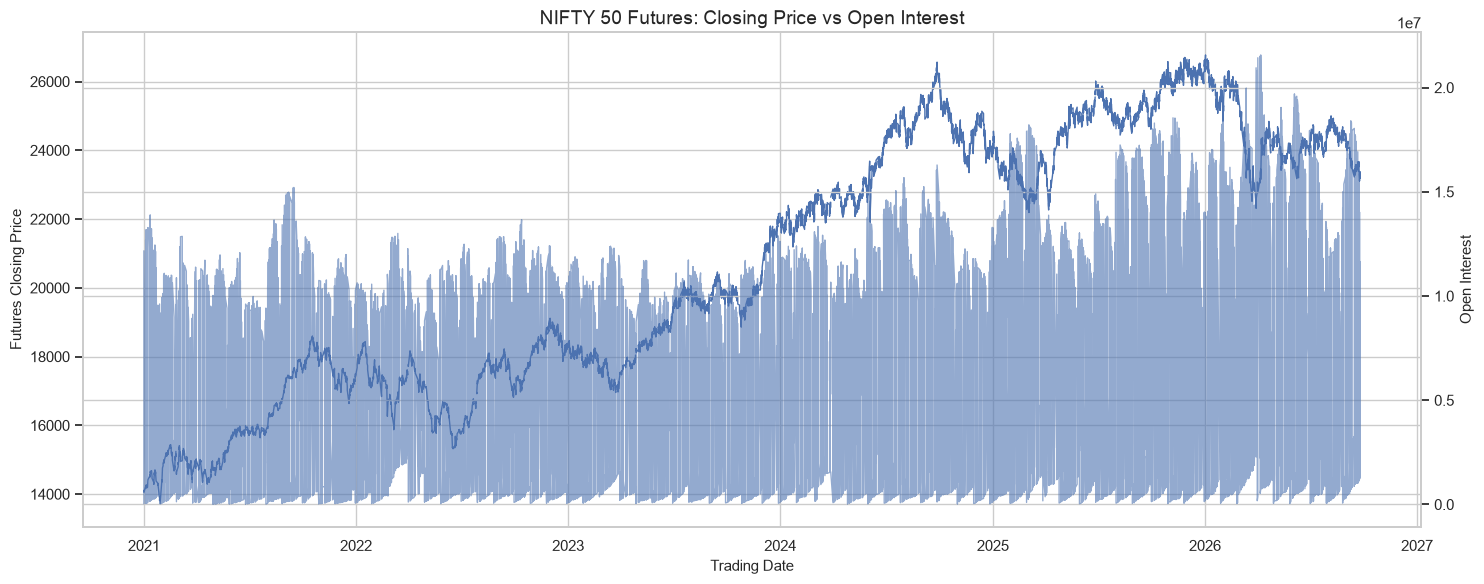

In [25]:
fig, ax1 = plt.subplots(figsize=(15, 6))

ax1.plot(
    futures_analysis["Date"],
    futures_analysis["Close"],
    label="Closing Price",
    linewidth=1
)

ax1.set_xlabel("Trading Date")
ax1.set_ylabel("Futures Closing Price")

ax2 = ax1.twinx()

ax2.plot(
    futures_analysis["Date"],
    futures_analysis["Open Int"],
    label="Open Interest",
    alpha=0.6,
    linewidth=1
)

ax2.set_ylabel("Open Interest")

plt.title("NIFTY 50 Futures: Closing Price vs Open Interest")
fig.tight_layout()
plt.show()

In [26]:
futures_summary = pd.DataFrame({
    "Metric": [
        "Mean Closing Price",
        "Median Closing Price",
        "Minimum Closing Price",
        "Maximum Closing Price",
        "Mean Daily Return (%)",
        "Daily Return Std Dev (%)",
        "Mean Open Interest",
        "Maximum Open Interest"
    ],
    "Value": [
        futures_analysis["Close"].mean(),
        futures_analysis["Close"].median(),
        futures_analysis["Close"].min(),
        futures_analysis["Close"].max(),
        futures_analysis["Daily_Return"].mean(),
        futures_analysis["Daily_Return"].std(),
        futures_analysis["Open Int"].mean(),
        futures_analysis["Open Int"].max()
    ]
})

display(futures_summary.round(4))

,Metric,Value
0,Mean Closing Price,"20,735.38"
1,Median Closing Price,"20,066.70"
2,Minimum Closing Price,"13,709.10"
3,Maximum Closing Price,"26,772.60"
4,Mean Daily Return (%),0.01
5,Daily Return Std Dev (%),0.79
6,Mean Open Interest,"4,978,355.12"
7,Maximum Open Interest,"21,563,945.00"


## 9. NIFTY 50 Call Options (CE) Analysis

This section explores NIFTY 50 Call Options (CE) over the study period
from January 2021 to September 2026.

The analysis focuses on:

- Call option price distributions.
- Closing price movements over time.
- Trading activity and contract volume.
- Open Interest behaviour.
- Strike price distribution.
- Expiry-wise market activity.

The objective is to identify patterns in call option trading and understand
how prices, trading activity, and outstanding positions vary across the market.

In [27]:
# Create a separate copy for CE analysis
calls_analysis = calls_df.copy()

# Sort records by trading date
calls_analysis = calls_analysis.sort_values("Date").reset_index(drop=True)

print("Call Options Dataset Shape:", calls_analysis.shape)

print("\nAvailable columns:")
print(calls_analysis.columns.tolist())

display(calls_analysis.head())

Call Options Dataset Shape: (1261810, 18)

Available columns:
['Symbol', 'Date', 'Expiry', 'Option type', 'Strike Price', 'Open', 'High', 'Low', 'Close', 'LTP', 'Settle Price', 'No. of contracts', 'Turnover * in ₹ Lakhs', 'Premium Turnover ** in ₹ Lakhs', 'Open Int', 'Change in OI', 'Underlying Value', 'source_file']


,Symbol,Date,Expiry,Option type,Strike Price,Open,High,Low,Close,LTP,Settle Price,No. of contracts,Turnover * in ₹ Lakhs,Premium Turnover ** in ₹ Lakhs,Open Int,Change in OI,Underlying Value,source_file
0,NIFTY,2021-01-01,2021-01-07,CE,"11,350.00",NaN,NaN,NaN,"1,115.65",NaN,"2,676.45",NaN,NaN,NaN,NaN,NaN,"14,018.50",Options_CE/2021/OPTIDX_NIFTY_CE_01-Jan-2021_TO...
1,NIFTY,2021-01-01,2021-01-28,CE,"13,850.00",405.95,415.00,390.05,398.70,400.40,398.70,130.00,"1,389.99",39.62,"18,675.00",900.00,"14,018.50",Options_CE/2021/OPTIDX_NIFTY_CE_01-Jan-2021_TO...
2,NIFTY,2021-01-01,2021-01-28,CE,"13,800.00",425.05,448.00,424.45,433.90,430.45,433.90,"3,143.00","33,565.83","1,035.78","431,250.00","-74,025.00","14,018.50",Options_CE/2021/OPTIDX_NIFTY_CE_01-Jan-2021_TO...
3,NIFTY,2021-01-01,2021-01-28,CE,"12,350.00",NaN,NaN,NaN,496.30,NaN,"1,716.05",NaN,NaN,NaN,NaN,NaN,"14,018.50",Options_CE/2021/OPTIDX_NIFTY_CE_01-Jan-2021_TO...
4,NIFTY,2021-01-01,2021-01-28,CE,"12,300.00","1,739.70","1,755.00","1,739.70","1,755.00","1,755.00","1,755.00",5.00,52.68,6.55,"17,625.00",75.00,"14,018.50",Options_CE/2021/OPTIDX_NIFTY_CE_01-Jan-2021_TO...


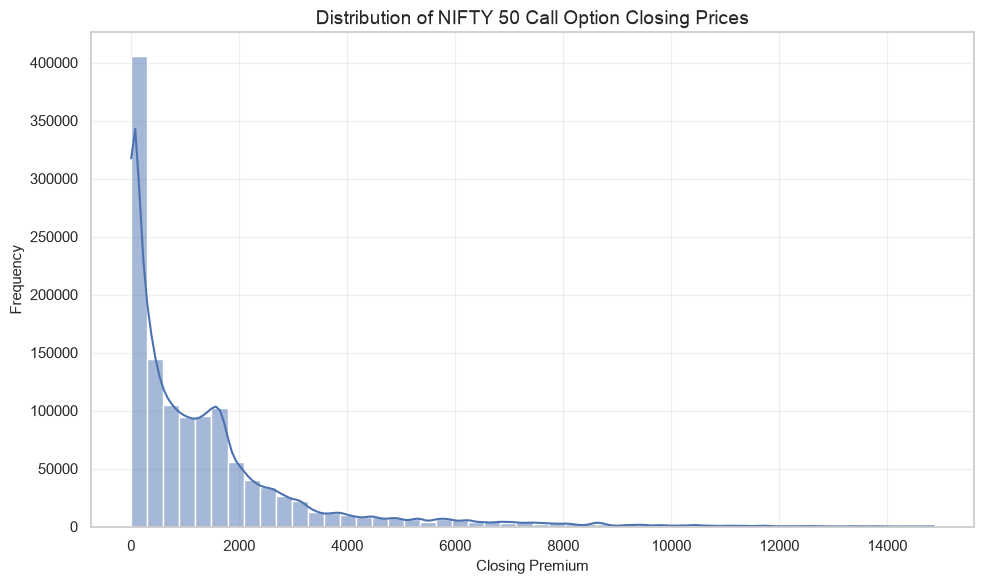

In [28]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=calls_analysis,
    x="Close",
    bins=50,
    kde=True
)

plt.title("Distribution of NIFTY 50 Call Option Closing Prices")
plt.xlabel("Closing Premium")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

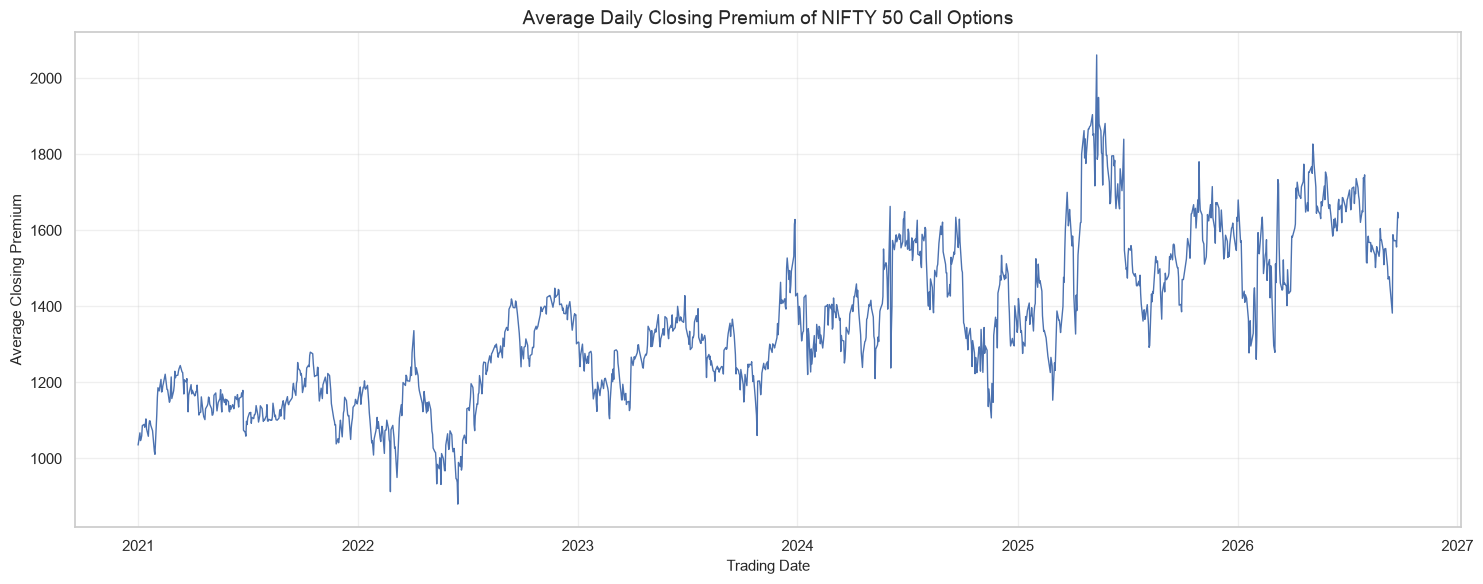

In [29]:
# Calculate daily average closing premium
ce_daily_price = (
    calls_analysis
    .groupby("Date")["Close"]
    .mean()
    .reset_index()
    .sort_values("Date")
)

plt.figure(figsize=(15, 6))

plt.plot(
    ce_daily_price["Date"],
    ce_daily_price["Close"],
    linewidth=1
)

plt.title("Average Daily Closing Premium of NIFTY 50 Call Options")
plt.xlabel("Trading Date")
plt.ylabel("Average Closing Premium")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

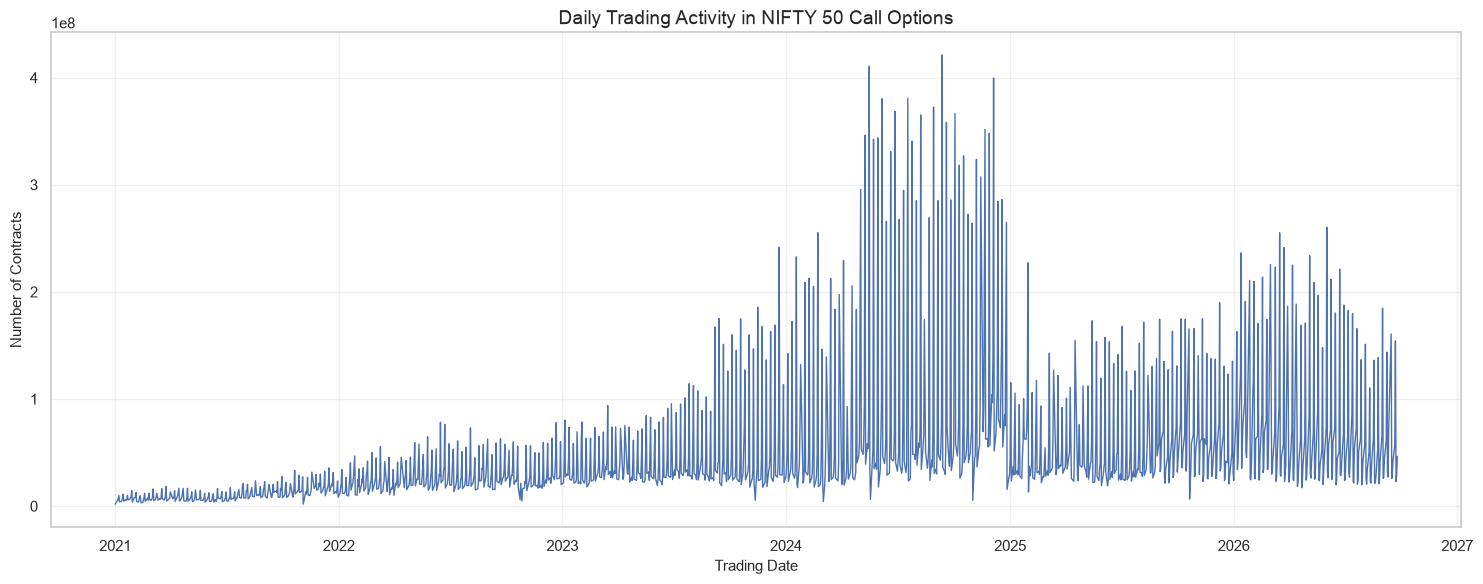

In [30]:
ce_daily_volume = (
    calls_analysis
    .groupby("Date")["No. of contracts"]
    .sum()
    .reset_index()
    .sort_values("Date")
)

plt.figure(figsize=(15, 6))

plt.plot(
    ce_daily_volume["Date"],
    ce_daily_volume["No. of contracts"],
    linewidth=1
)

plt.title("Daily Trading Activity in NIFTY 50 Call Options")
plt.xlabel("Trading Date")
plt.ylabel("Number of Contracts")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

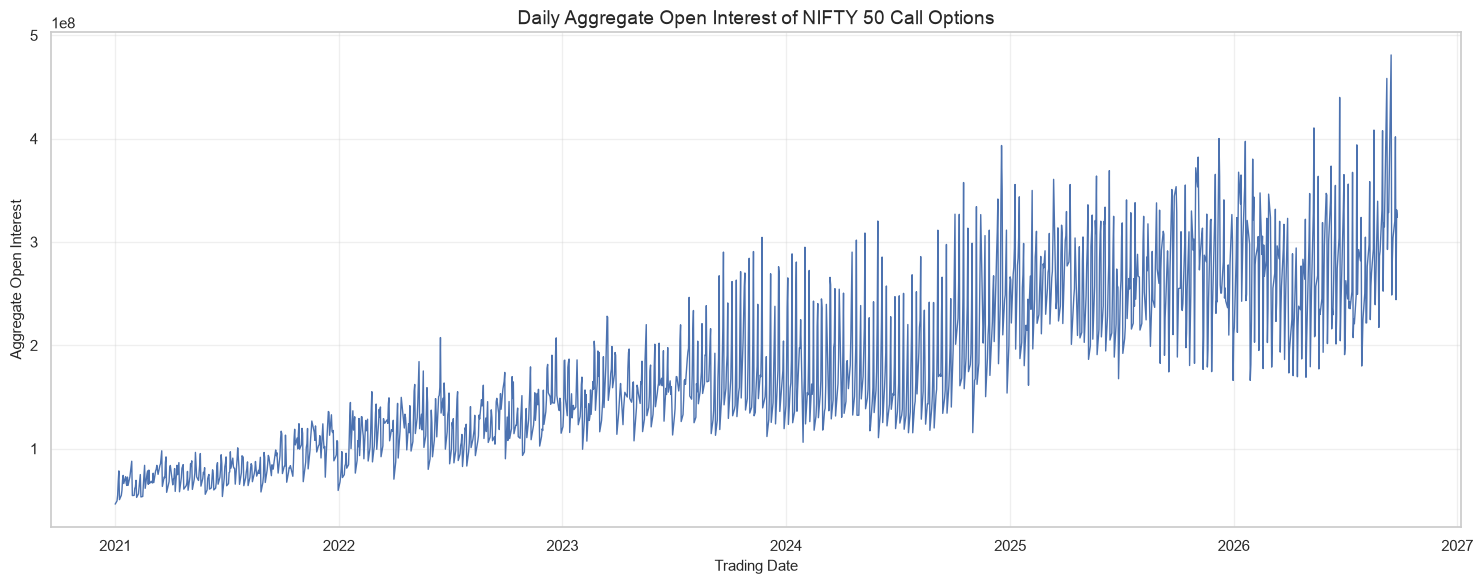

In [31]:
ce_daily_oi = (
    calls_analysis
    .groupby("Date")["Open Int"]
    .sum()
    .reset_index()
    .sort_values("Date")
)

plt.figure(figsize=(15, 6))

plt.plot(
    ce_daily_oi["Date"],
    ce_daily_oi["Open Int"],
    linewidth=1
)

plt.title("Daily Aggregate Open Interest of NIFTY 50 Call Options")
plt.xlabel("Trading Date")
plt.ylabel("Aggregate Open Interest")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

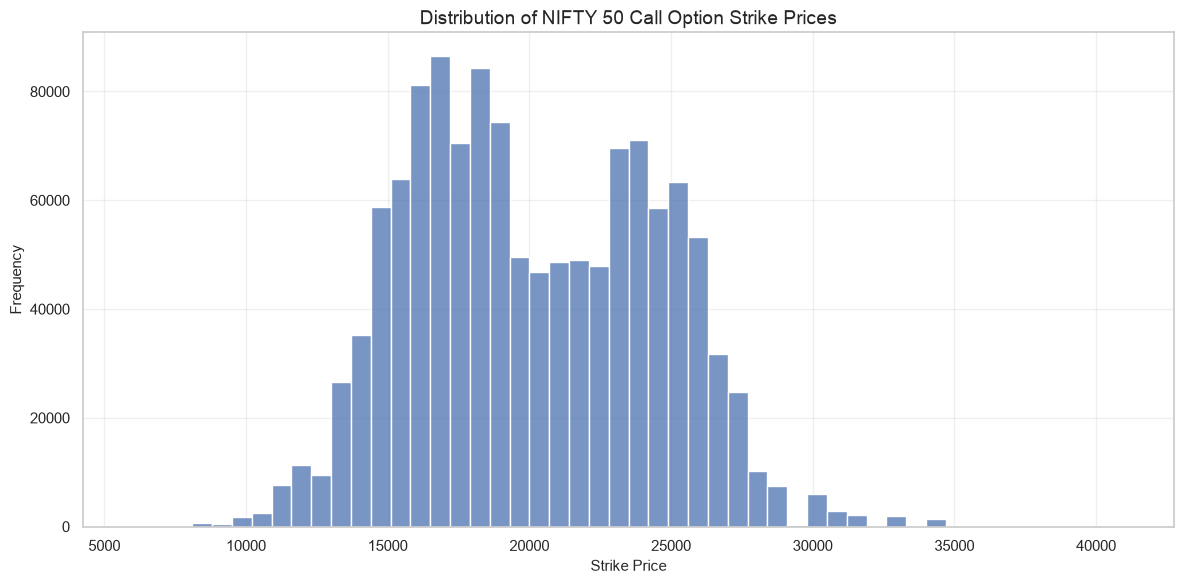

In [32]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=calls_analysis,
    x="Strike Price",
    bins=50
)

plt.title("Distribution of NIFTY 50 Call Option Strike Prices")
plt.xlabel("Strike Price")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
top_ce_strikes = (
    calls_analysis["Strike Price"]
    .value_counts()
    .head(15)
    .sort_values(ascending=False)
)

display(
    top_ce_strikes.rename("Number of Records").to_frame()
)

,Number of Records
Strike Price,
"18,000.00",18933
"19,000.00",17171
"21,000.00",16676
"17,000.00",16233
"16,000.00",15686
"23,000.00",15478
"20,000.00",15023
"22,000.00",14498
"24,000.00",14107


In [34]:
ce_expiry_summary = (
    calls_analysis
    .groupby("Expiry")
    .agg(
        Number_of_Records=("Strike Price", "count"),
        Total_Contracts=("No. of contracts", "sum"),
        Average_Closing_Premium=("Close", "mean"),
        Total_Open_Interest=("Open Int", "sum")
    )
    .reset_index()
    .sort_values("Expiry")
)

display(ce_expiry_summary.head(15))

,Expiry,Number_of_Records,Total_Contracts,Average_Closing_Premium,Total_Open_Interest
0,2021-01-07,506,"26,301,156.00",838.70,"151,205,175.00"
1,2021-01-14,930,"30,706,335.00",728.81,"191,207,100.00"
2,2021-01-21,1413,"29,877,623.00",662.91,"209,762,925.00"
3,2021-01-28,2227,"39,623,844.00","1,159.72","533,693,400.00"
4,2021-02-04,2115,"37,481,692.00",636.83,"193,431,075.00"
5,2021-02-11,2497,"30,810,942.00",685.41,"186,259,275.00"
6,2021-02-18,2991,"29,267,994.00",760.69,"186,188,250.00"
7,2021-02-25,3803,"41,145,334.00",988.63,"615,109,800.00"
8,2021-03-04,3687,"40,915,077.00",673.16,"236,385,900.00"
9,2021-03-10,3616,"31,653,908.00",724.94,"203,790,900.00"


In [35]:
ce_summary = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Mean Closing Premium",
        "Median Closing Premium",
        "Minimum Closing Premium",
        "Maximum Closing Premium",
        "Total Contracts Traded",
        "Average Open Interest",
        "Maximum Open Interest",
        "Number of Unique Strike Prices",
        "Number of Unique Expiry Dates"
    ],
    "Value": [
        len(calls_analysis),
        calls_analysis["Close"].mean(),
        calls_analysis["Close"].median(),
        calls_analysis["Close"].min(),
        calls_analysis["Close"].max(),
        calls_analysis["No. of contracts"].sum(),
        calls_analysis["Open Int"].mean(),
        calls_analysis["Open Int"].max(),
        calls_analysis["Strike Price"].nunique(),
        calls_analysis["Expiry"].nunique()
    ]
})

display(ce_summary.round(3))

,Metric,Value
0,Total Records,"1,261,810.00"
1,Mean Closing Premium,"1,341.41"
2,Median Closing Premium,791.90
3,Minimum Closing Premium,0.05
4,Maximum Closing Premium,"14,862.95"
5,Total Contracts Traded,"73,404,424,377.00"
6,Average Open Interest,"362,453.85"
7,Maximum Open Interest,"44,955,170.00"
8,Number of Unique Strike Prices,437.00
9,Number of Unique Expiry Dates,331.00


## 10. NIFTY 50 Put Options (PE) Analysis

This section explores NIFTY 50 Put Options (PE) over the study period
from January 2021 to September 2026.

The analysis focuses on:

- Put option closing price distributions.
- Daily average closing premium.
- Trading activity and contract volume.
- Open Interest behaviour.
- Strike price distribution.
- Expiry-wise market activity.

The objective is to understand the behaviour of put options and identify
patterns in their prices, trading activity, and outstanding positions.

In [36]:
# Create a separate copy for PE analysis
puts_analysis = puts_df.copy()

# Sort records by trading date
puts_analysis = puts_analysis.sort_values("Date").reset_index(drop=True)

print("Put Options Dataset Shape:", puts_analysis.shape)

print("\nAvailable columns:")
print(puts_analysis.columns.tolist())

display(puts_analysis.head())

Put Options Dataset Shape: (1300689, 18)

Available columns:
['Symbol', 'Date', 'Expiry', 'Option type', 'Strike Price', 'Open', 'High', 'Low', 'Close', 'LTP', 'Settle Price', 'No. of contracts', 'Turnover * in ₹ Lakhs', 'Premium Turnover ** in ₹ Lakhs', 'Open Int', 'Change in OI', 'Underlying Value', 'source_file']


,Symbol,Date,Expiry,Option type,Strike Price,Open,High,Low,Close,LTP,Settle Price,No. of contracts,Turnover * in ₹ Lakhs,Premium Turnover ** in ₹ Lakhs,Open Int,Change in OI,Underlying Value,source_file
0,NIFTY,2021-01-01,2021-01-14,PE,"14,500.00",519.00,527.00,479.60,489.55,491.75,489.55,41.00,461.57,15.70,"1,650.00","1,350.00","14,018.50",Options_PE/2021/OPTIDX_NIFTY_PE_01-Jan-2021_TO...
1,NIFTY,2021-01-01,2021-02-04,PE,"14,700.00",NaN,NaN,NaN,"1,559.15",NaN,811.30,NaN,NaN,NaN,NaN,NaN,"14,018.50",Options_PE/2021/OPTIDX_NIFTY_PE_01-Jan-2021_TO...
2,NIFTY,2021-01-01,2021-01-28,PE,"12,950.00",47.20,47.25,31.15,33.65,35.70,33.65,396.00,"3,856.29",10.14,"13,725.00","11,400.00","14,018.50",Options_PE/2021/OPTIDX_NIFTY_PE_01-Jan-2021_TO...
3,NIFTY,2021-01-01,2021-01-28,PE,"11,400.00",3.65,5.45,3.65,3.65,3.65,0.20,18.00,153.96,0.06,"11,100.00",NaN,"14,018.50",Options_PE/2021/OPTIDX_NIFTY_PE_01-Jan-2021_TO...
4,NIFTY,2021-01-01,2021-01-28,PE,"11,350.00",NaN,NaN,NaN,520.20,NaN,0.15,NaN,NaN,NaN,NaN,NaN,"14,018.50",Options_PE/2021/OPTIDX_NIFTY_PE_01-Jan-2021_TO...


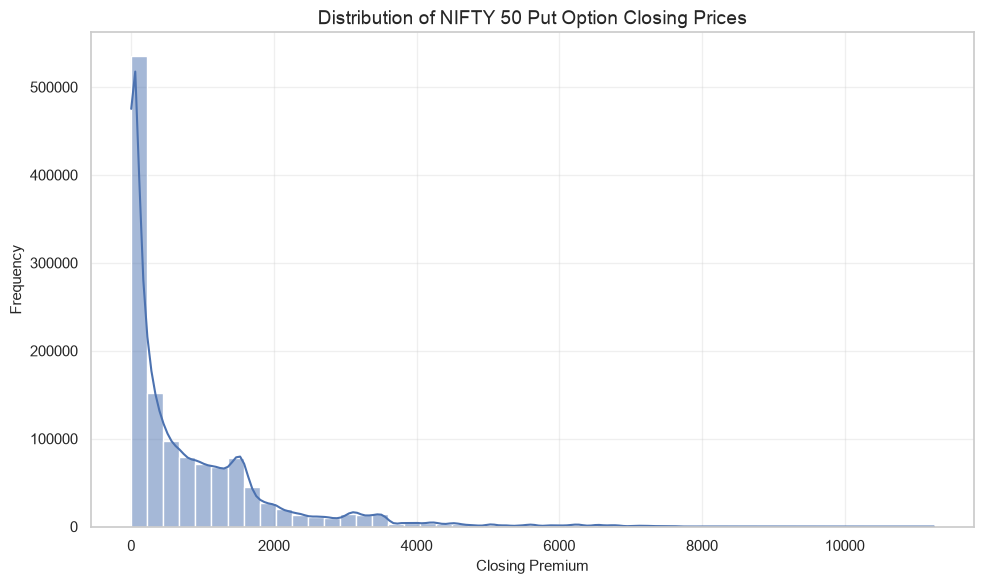

In [37]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=puts_analysis,
    x="Close",
    bins=50,
    kde=True
)

plt.title("Distribution of NIFTY 50 Put Option Closing Prices")
plt.xlabel("Closing Premium")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

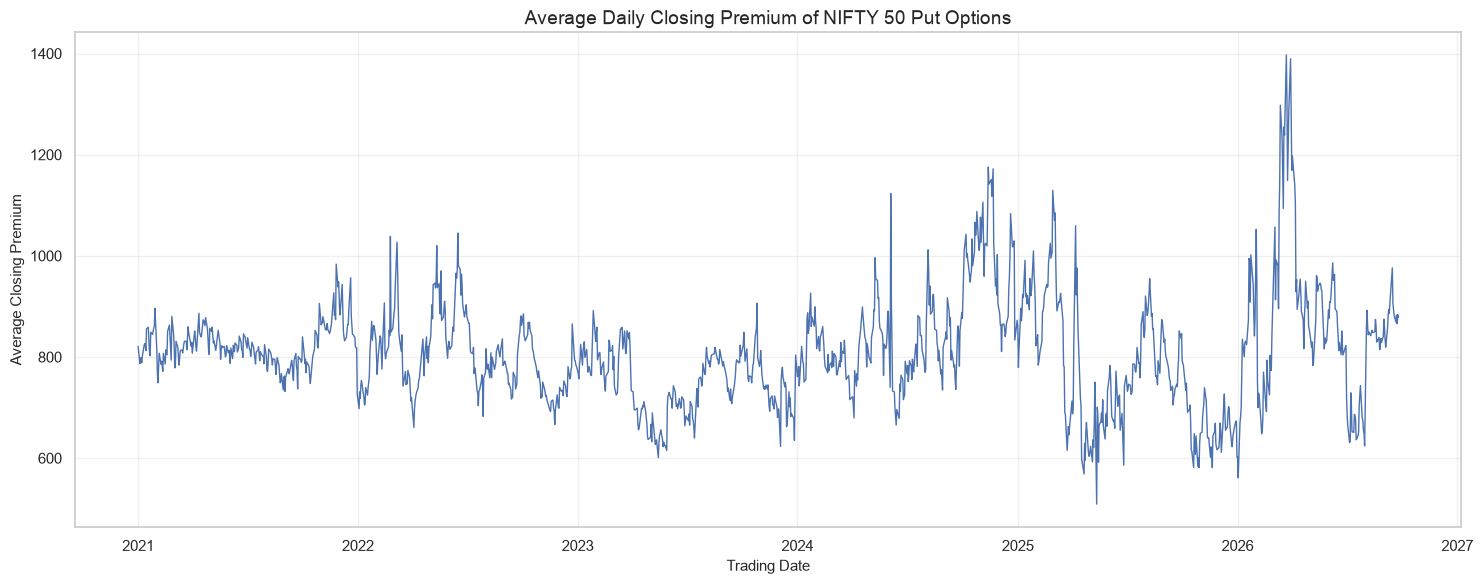

In [38]:
# Calculate daily average closing premium
pe_daily_price = (
    puts_analysis
    .groupby("Date")["Close"]
    .mean()
    .reset_index()
    .sort_values("Date")
)

plt.figure(figsize=(15, 6))

plt.plot(
    pe_daily_price["Date"],
    pe_daily_price["Close"],
    linewidth=1
)

plt.title("Average Daily Closing Premium of NIFTY 50 Put Options")
plt.xlabel("Trading Date")
plt.ylabel("Average Closing Premium")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

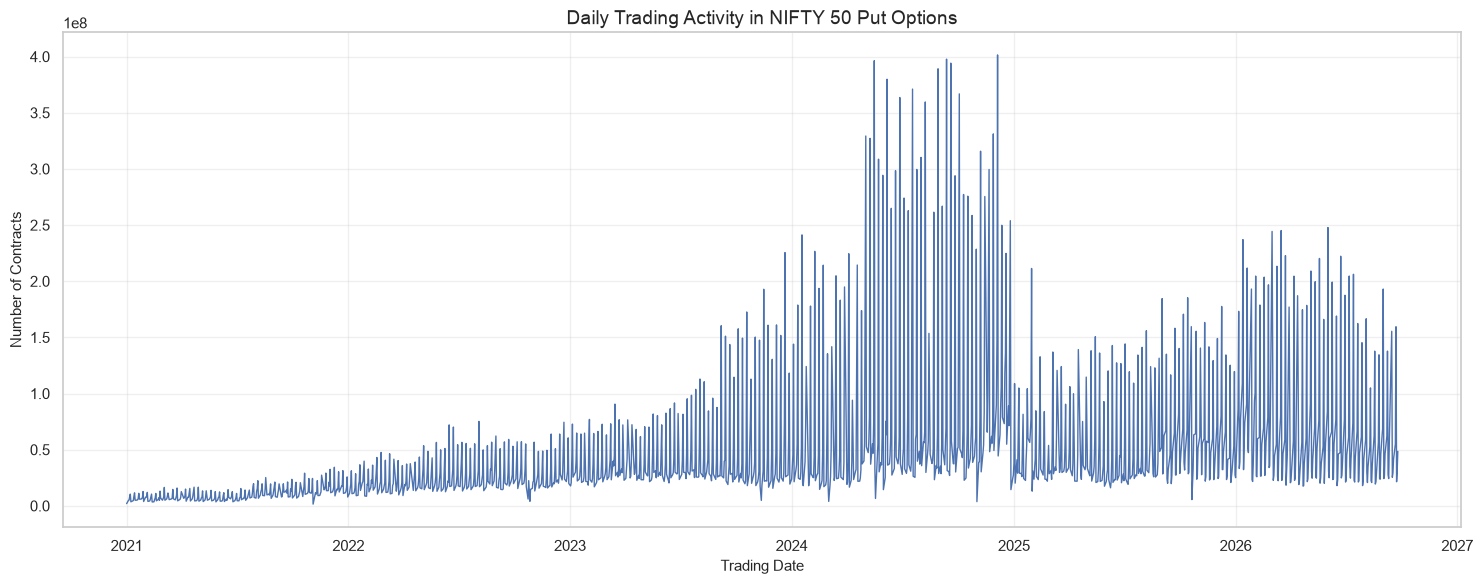

In [39]:
pe_daily_volume = (
    puts_analysis
    .groupby("Date")["No. of contracts"]
    .sum()
    .reset_index()
    .sort_values("Date")
)

plt.figure(figsize=(15, 6))

plt.plot(
    pe_daily_volume["Date"],
    pe_daily_volume["No. of contracts"],
    linewidth=1
)

plt.title("Daily Trading Activity in NIFTY 50 Put Options")
plt.xlabel("Trading Date")
plt.ylabel("Number of Contracts")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

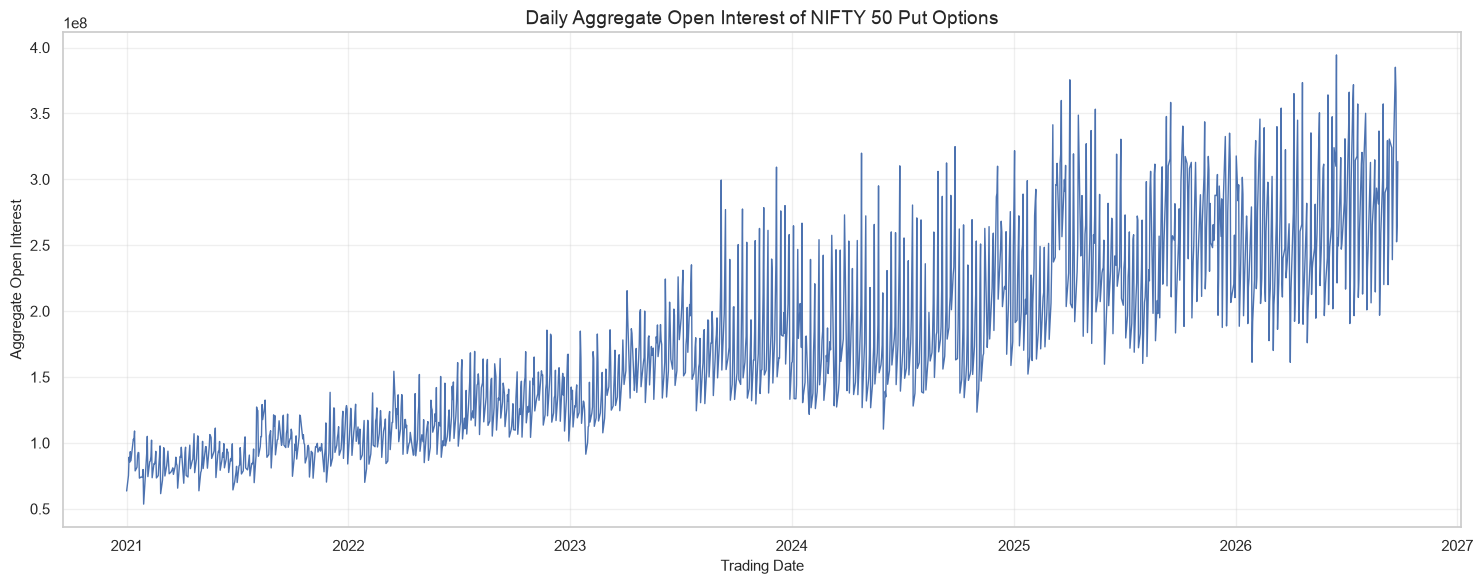

In [40]:
pe_daily_oi = (
    puts_analysis
    .groupby("Date")["Open Int"]
    .sum()
    .reset_index()
    .sort_values("Date")
)

plt.figure(figsize=(15, 6))

plt.plot(
    pe_daily_oi["Date"],
    pe_daily_oi["Open Int"],
    linewidth=1
)

plt.title("Daily Aggregate Open Interest of NIFTY 50 Put Options")
plt.xlabel("Trading Date")
plt.ylabel("Aggregate Open Interest")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

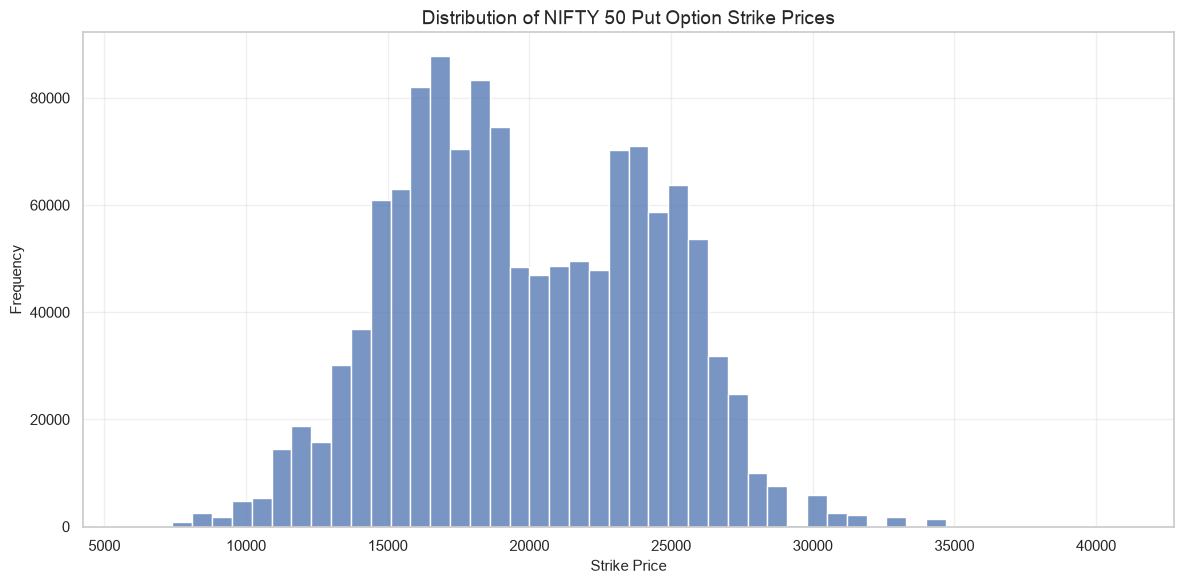

In [41]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=puts_analysis,
    x="Strike Price",
    bins=50
)

plt.title("Distribution of NIFTY 50 Put Option Strike Prices")
plt.xlabel("Strike Price")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [42]:
top_pe_strikes = (
    puts_analysis["Strike Price"]
    .value_counts()
    .head(15)
    .sort_values(ascending=False)
)

display(
    top_pe_strikes.rename("Number of Records").to_frame()
)

,Number of Records
Strike Price,
"18,000.00",19532
"19,000.00",17385
"17,000.00",17023
"21,000.00",16675
"16,000.00",16472
"15,000.00",16275
"23,000.00",16128
"20,000.00",15521
"22,000.00",15095


In [43]:
pe_expiry_summary = (
    puts_analysis
    .groupby("Expiry")
    .agg(
        Number_of_Records=("Strike Price", "count"),
        Total_Contracts=("No. of contracts", "sum"),
        Average_Closing_Premium=("Close", "mean"),
        Total_Open_Interest=("Open Int", "sum")
    )
    .reset_index()
    .sort_values("Expiry")
)

display(pe_expiry_summary.head(15))

,Expiry,Number_of_Records,Total_Contracts,Average_Closing_Premium,Total_Open_Interest
0,2021-01-07,506,"27,065,483.00",282.00,"147,745,200.00"
1,2021-01-14,930,"30,712,846.00",362.23,"234,823,050.00"
2,2021-01-21,1413,"29,650,546.00",463.40,"177,566,175.00"
3,2021-01-28,2227,"37,561,007.00",322.90,"622,113,375.00"
4,2021-02-04,2115,"36,365,057.00",642.32,"208,710,975.00"
5,2021-02-11,2497,"31,025,801.00",646.85,"192,317,475.00"
6,2021-02-18,2991,"27,945,380.00",605.86,"169,203,000.00"
7,2021-02-25,3803,"41,873,401.00",468.52,"811,118,325.00"
8,2021-03-04,3687,"39,931,359.00",731.22,"193,639,950.00"
9,2021-03-10,3616,"29,703,279.00",681.20,"144,883,275.00"


In [44]:
pe_summary = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Mean Closing Premium",
        "Median Closing Premium",
        "Minimum Closing Premium",
        "Maximum Closing Premium",
        "Total Contracts Traded",
        "Average Open Interest",
        "Maximum Open Interest",
        "Number of Unique Strike Prices",
        "Number of Unique Expiry Dates"
    ],
    "Value": [
        len(puts_analysis),
        puts_analysis["Close"].mean(),
        puts_analysis["Close"].median(),
        puts_analysis["Close"].min(),
        puts_analysis["Close"].max(),
        puts_analysis["No. of contracts"].sum(),
        puts_analysis["Open Int"].mean(),
        puts_analysis["Open Int"].max(),
        puts_analysis["Strike Price"].nunique(),
        puts_analysis["Expiry"].nunique()
    ]
})

display(pe_summary.round(3))

,Metric,Value
0,Total Records,"1,300,689.00"
1,Mean Closing Premium,810.59
2,Median Closing Premium,371.10
3,Minimum Closing Premium,0.05
4,Maximum Closing Premium,"11,250.00"
5,Total Contracts Traded,"69,913,372,822.00"
6,Average Open Interest,"326,762.38"
7,Maximum Open Interest,"39,182,025.00"
8,Number of Unique Strike Prices,450.00
9,Number of Unique Expiry Dates,331.00


## 11. Open Interest and Strike Price Analysis

This section examines the distribution of Open Interest (OI) across
different strike prices in NIFTY 50 options.

The analysis focuses on:

- Call and Put Open Interest across strike prices.
- Identification of strike prices with the highest Open Interest.
- Comparison of Call and Put Open Interest.
- Relationship between trading volume and Open Interest.
- Changes in Open Interest over time.

The objective is to identify concentrations of outstanding positions
and understand how these vary across strike prices.

In [45]:
# Aggregate Open Interest by strike price
ce_oi_by_strike = (
    calls_analysis
    .groupby("Strike Price")["Open Int"]
    .sum()
    .rename("CE_Open_Interest")
)

pe_oi_by_strike = (
    puts_analysis
    .groupby("Strike Price")["Open Int"]
    .sum()
    .rename("PE_Open_Interest")
)

# Combine CE and PE data
oi_by_strike = pd.concat(
    [ce_oi_by_strike, pe_oi_by_strike],
    axis=1
).fillna(0)

display(oi_by_strike.head(10))

,CE_Open_Interest,PE_Open_Interest
Strike Price,,
"6,000.00",0.00,"443,025.00"
"7,000.00",0.00,0.00
"8,000.00","58,650.00","3,680,575.00"
"8,500.00","35,611,950.00","62,015,900.00"
"9,000.00","2,349,425.00","206,507,600.00"
"9,500.00","2,577,075.00","59,131,875.00"
"10,000.00","97,024,825.00","247,177,475.00"
"10,100.00","19,950.00","346,350.00"
"10,150.00","89,250.00","669,525.00"


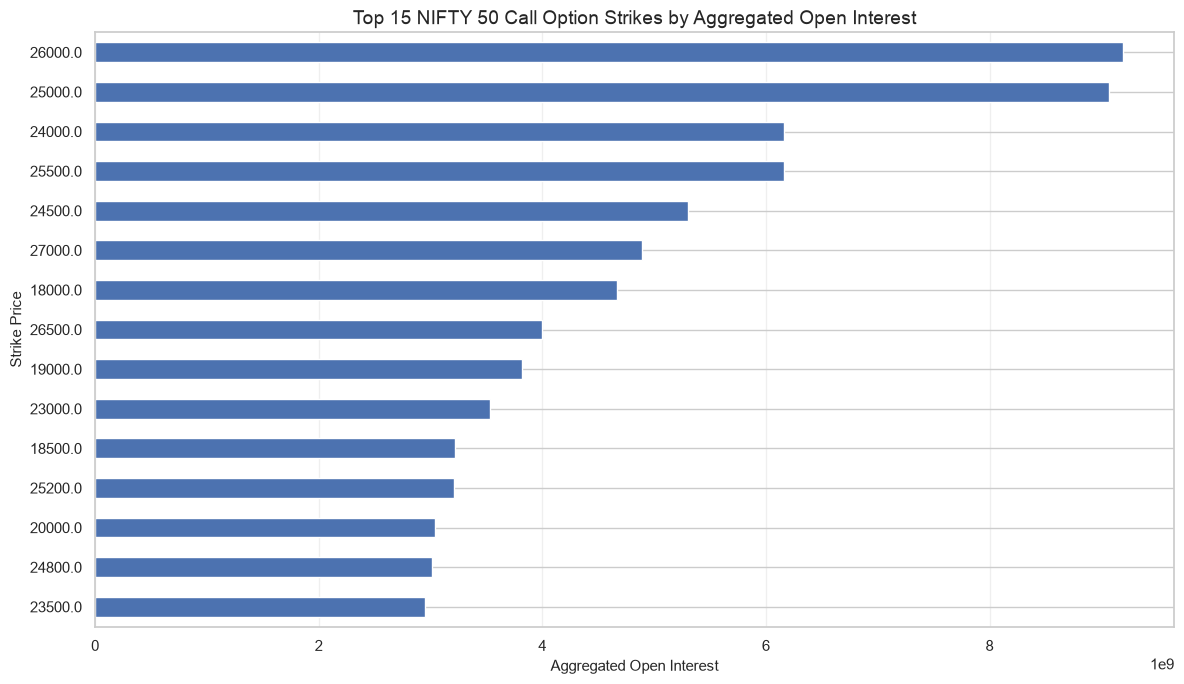

In [46]:
top_ce_oi = (
    oi_by_strike["CE_Open_Interest"]
    .nlargest(15)
    .sort_values(ascending=True)
)

plt.figure(figsize=(12, 7))

top_ce_oi.plot(kind="barh")

plt.title("Top 15 NIFTY 50 Call Option Strikes by Aggregated Open Interest")
plt.xlabel("Aggregated Open Interest")
plt.ylabel("Strike Price")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

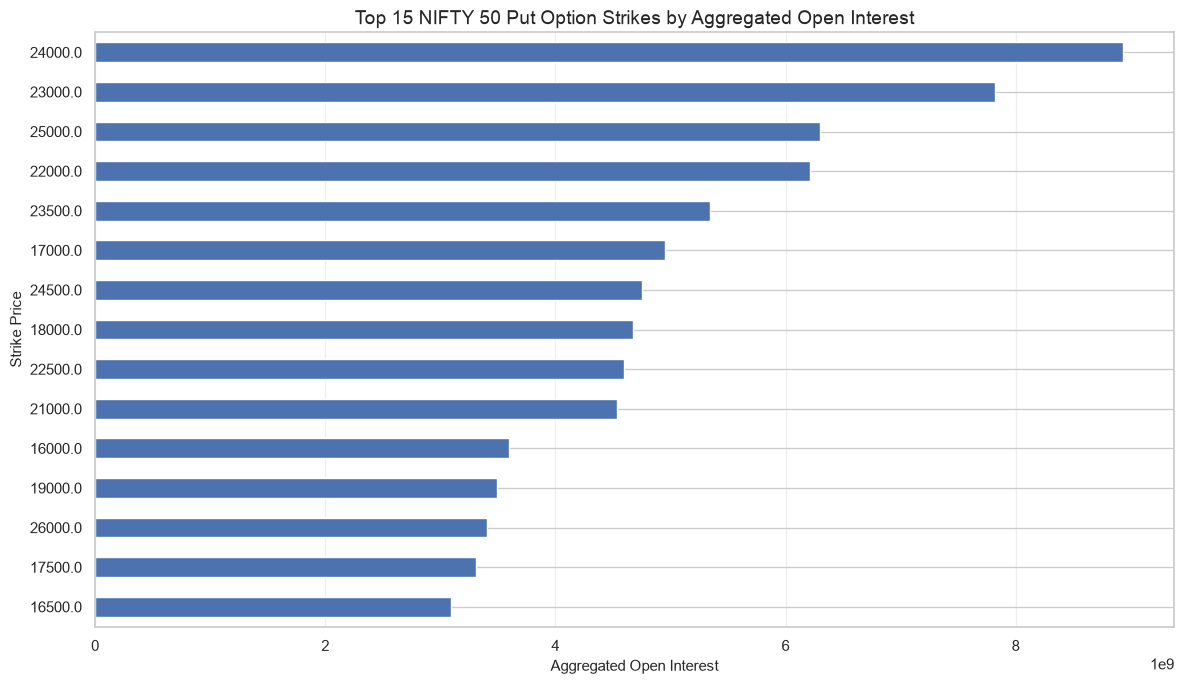

In [47]:
top_pe_oi = (
    oi_by_strike["PE_Open_Interest"]
    .nlargest(15)
    .sort_values(ascending=True)
)

plt.figure(figsize=(12, 7))

top_pe_oi.plot(kind="barh")

plt.title("Top 15 NIFTY 50 Put Option Strikes by Aggregated Open Interest")
plt.xlabel("Aggregated Open Interest")
plt.ylabel("Strike Price")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

,CE_Open_Interest,PE_Open_Interest,Total_OI
Strike Price,,,
"17,000.00","2,220,068,000.00","4,952,967,790.00","7,173,035,790.00"
"18,000.00","4,665,054,010.00","4,675,407,800.00","9,340,461,810.00"
"19,000.00","3,817,309,380.00","3,492,947,820.00","7,310,257,200.00"
"20,000.00","3,038,837,370.00","3,017,428,660.00","6,056,266,030.00"
"21,000.00","1,819,762,535.00","4,539,024,515.00","6,358,787,050.00"
"22,000.00","2,133,247,260.00","6,215,260,925.00","8,348,508,185.00"
"22,500.00","2,008,979,900.00","4,592,485,425.00","6,601,465,325.00"
"23,000.00","3,532,335,540.00","7,823,719,635.00","11,356,055,175.00"
"23,500.00","2,954,167,700.00","5,347,428,875.00","8,301,596,575.00"


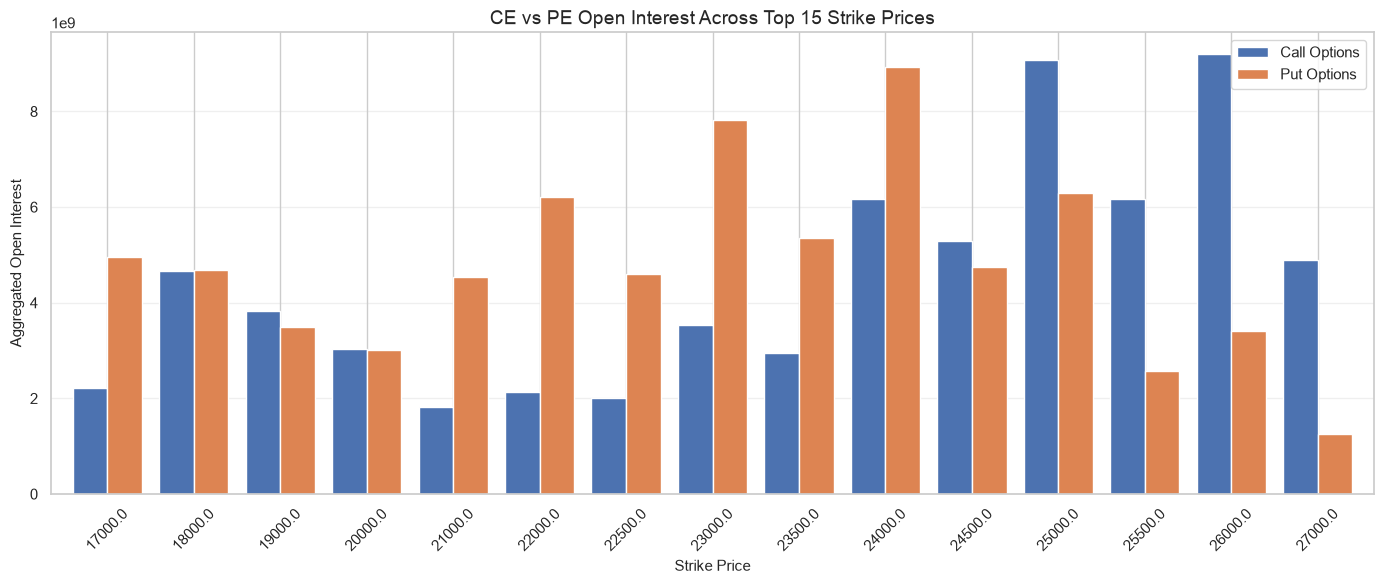

In [48]:
top_combined_strikes = (
    oi_by_strike
    .assign(
        Total_OI=lambda x:
        x["CE_Open_Interest"] + x["PE_Open_Interest"]
    )
    .nlargest(15, "Total_OI")
    .sort_values("Strike Price")
)

display(top_combined_strikes)

top_combined_strikes[
    ["CE_Open_Interest", "PE_Open_Interest"]
].plot(
    kind="bar",
    figsize=(14, 6),
    width=0.8
)

plt.title("CE vs PE Open Interest Across Top 15 Strike Prices")
plt.xlabel("Strike Price")
plt.ylabel("Aggregated Open Interest")
plt.xticks(rotation=45)
plt.legend(["Call Options", "Put Options"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

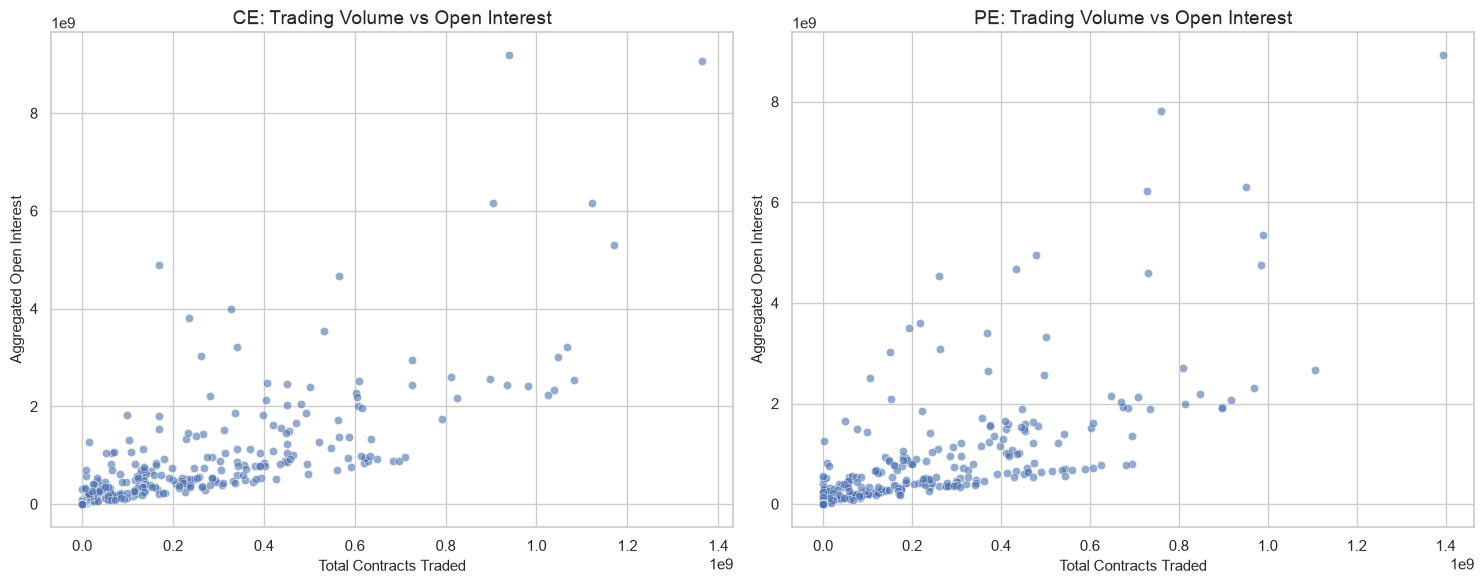

In [49]:
# Calculate total contracts traded and Open Interest by strike
ce_strike_activity = (
    calls_analysis
    .groupby("Strike Price")
    .agg(
        Contracts_Traded=("No. of contracts", "sum"),
        Open_Interest=("Open Int", "sum")
    )
)

pe_strike_activity = (
    puts_analysis
    .groupby("Strike Price")
    .agg(
        Contracts_Traded=("No. of contracts", "sum"),
        Open_Interest=("Open Int", "sum")
    )
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(
    data=ce_strike_activity,
    x="Contracts_Traded",
    y="Open_Interest",
    ax=axes[0],
    alpha=0.6
)

axes[0].set_title("CE: Trading Volume vs Open Interest")
axes[0].set_xlabel("Total Contracts Traded")
axes[0].set_ylabel("Aggregated Open Interest")

sns.scatterplot(
    data=pe_strike_activity,
    x="Contracts_Traded",
    y="Open_Interest",
    ax=axes[1],
    alpha=0.6
)

axes[1].set_title("PE: Trading Volume vs Open Interest")
axes[1].set_xlabel("Total Contracts Traded")
axes[1].set_ylabel("Aggregated Open Interest")

plt.tight_layout()
plt.show()

In [51]:
# Select the latest available common trading date
common_dates = sorted(
    set(calls_analysis["Date"].dropna())
    & set(puts_analysis["Date"].dropna())
)

snapshot_date = common_dates[-1]

print("Selected Snapshot Date:", snapshot_date)

# Filter CE and PE records for that date
ce_snapshot = calls_analysis[
    calls_analysis["Date"] == snapshot_date
]

pe_snapshot = puts_analysis[
    puts_analysis["Date"] == snapshot_date
]

# Aggregate OI by strike
ce_snapshot_oi = (
    ce_snapshot.groupby("Strike Price")["Open Int"]
    .sum()
    .rename("CE_Open_Interest")
)

pe_snapshot_oi = (
    pe_snapshot.groupby("Strike Price")["Open Int"]
    .sum()
    .rename("PE_Open_Interest")
)

snapshot_oi = pd.concat(
    [ce_snapshot_oi, pe_snapshot_oi],
    axis=1
).fillna(0)

display(snapshot_oi.head(10))

Selected Snapshot Date: 2026-09-25 00:00:00


,CE_Open_Interest,PE_Open_Interest
Strike Price,,
"15,000.00",0.00,"265,225.00"
"16,000.00",260.00,"126,290.00"
"16,500.00",0.00,"161,915.00"
"18,000.00","3,380.00","1,572,375.00"
"19,000.00","140,930.00","869,610.00"
"19,500.00","97,825.00","1,264,835.00"
"20,000.00","703,390.00","1,533,830.00"
"20,800.00",0.00,"2,366,975.00"
"20,850.00",0.00,"28,145.00"


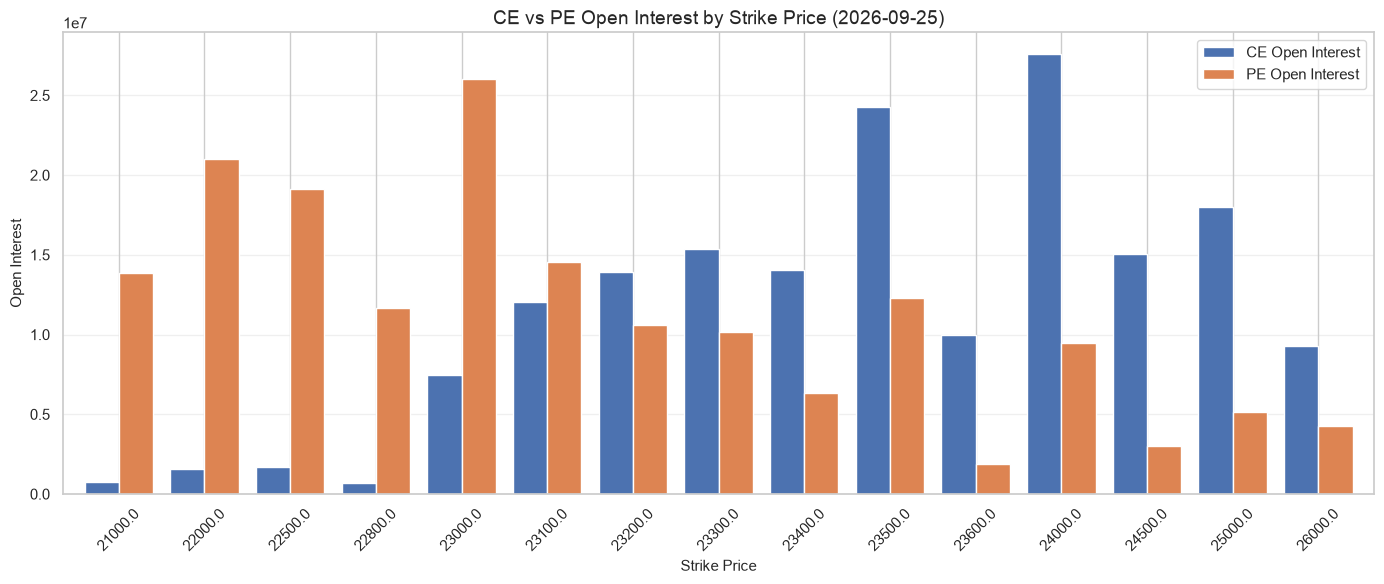

In [52]:
snapshot_top = (
    snapshot_oi
    .assign(
        Total_OI=lambda x:
        x["CE_Open_Interest"] + x["PE_Open_Interest"]
    )
    .nlargest(15, "Total_OI")
    .sort_index()
)

snapshot_top[
    ["CE_Open_Interest", "PE_Open_Interest"]
].plot(
    kind="bar",
    figsize=(14, 6),
    width=0.8
)

plt.title(f"CE vs PE Open Interest by Strike Price ({snapshot_date.date()})")
plt.xlabel("Strike Price")
plt.ylabel("Open Interest")
plt.xticks(rotation=45)
plt.legend(["CE Open Interest", "PE Open Interest"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [53]:
total_ce_oi = snapshot_oi["CE_Open_Interest"].sum()
total_pe_oi = snapshot_oi["PE_Open_Interest"].sum()

pcr_oi = (
    total_pe_oi / total_ce_oi
    if total_ce_oi != 0
    else np.nan
)

pcr_summary = pd.DataFrame({
    "Metric": [
        "Total CE Open Interest",
        "Total PE Open Interest",
        "Open Interest PCR"
    ],
    "Value": [
        total_ce_oi,
        total_pe_oi,
        pcr_oi
    ]
})

display(pcr_summary.round(4))

,Metric,Value
0,Total CE Open Interest,"323,816,435.00"
1,Total PE Open Interest,"313,507,905.00"
2,Open Interest PCR,0.97


## 12. Price Distribution and Volatility Analysis

This section examines price variability and volatility across the NIFTY
derivatives market.

The analysis focuses on:

- Distribution of futures returns.
- Volatility of futures contracts.
- Rolling volatility patterns.
- Distribution of CE and PE option premiums.
- Statistical characteristics of futures returns.

Returns are calculated separately within each futures expiry contract
to avoid comparing prices from different contracts.

In [54]:
# Sort futures observations by expiry and trading date
futures_volatility = futures_df.copy()

futures_volatility = futures_volatility.sort_values(
    ["Expiry", "Date"]
).reset_index(drop=True)

# Calculate returns separately for each expiry contract
futures_volatility["Daily_Return"] = (
    futures_volatility
    .groupby("Expiry")["Close"]
    .pct_change() * 100
)

display(
    futures_volatility[
        ["Date", "Expiry", "Close", "Daily_Return"]
    ].head(15)
)

,Date,Expiry,Close,Daily_Return
0,2021-01-01,2021-01-28,"14,053.85",NaN
1,2021-01-04,2021-01-28,"14,165.30",0.79
2,2021-01-05,2021-01-28,"14,217.95",0.37
3,2021-01-06,2021-01-28,"14,189.45",-0.20
4,2021-01-07,2021-01-28,"14,191.10",0.01
5,2021-01-08,2021-01-28,"14,370.90",1.27
6,2021-01-11,2021-01-28,"14,489.25",0.82
7,2021-01-12,2021-01-28,"14,597.95",0.75
8,2021-01-13,2021-01-28,"14,606.15",0.06
9,2021-01-14,2021-01-28,"14,628.10",0.15


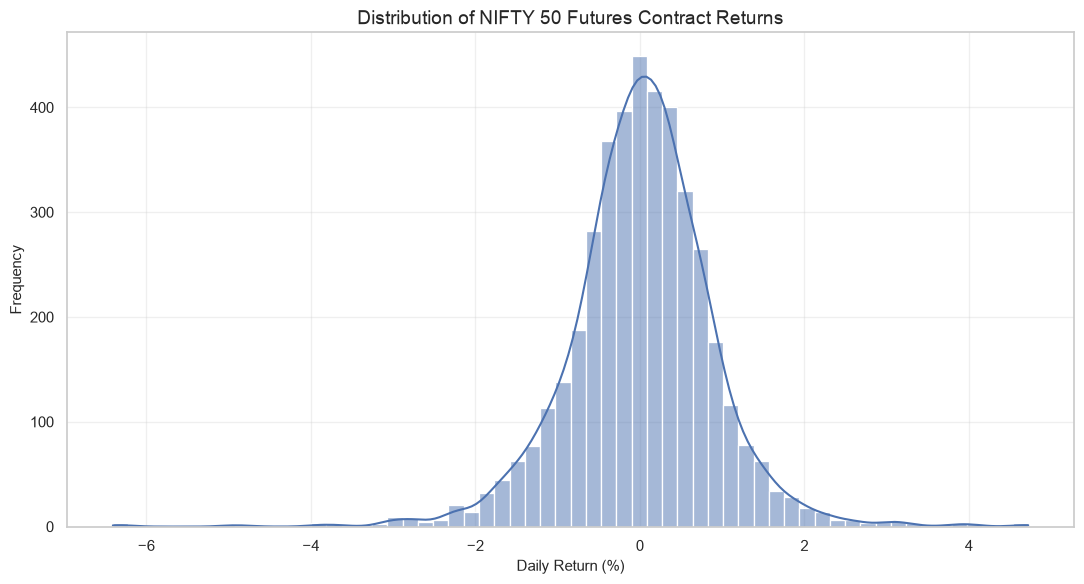

In [55]:
futures_returns = (
    futures_volatility["Daily_Return"]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

plt.figure(figsize=(11, 6))

sns.histplot(
    futures_returns,
    bins=60,
    kde=True
)

plt.title("Distribution of NIFTY 50 Futures Contract Returns")
plt.xlabel("Daily Return (%)")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

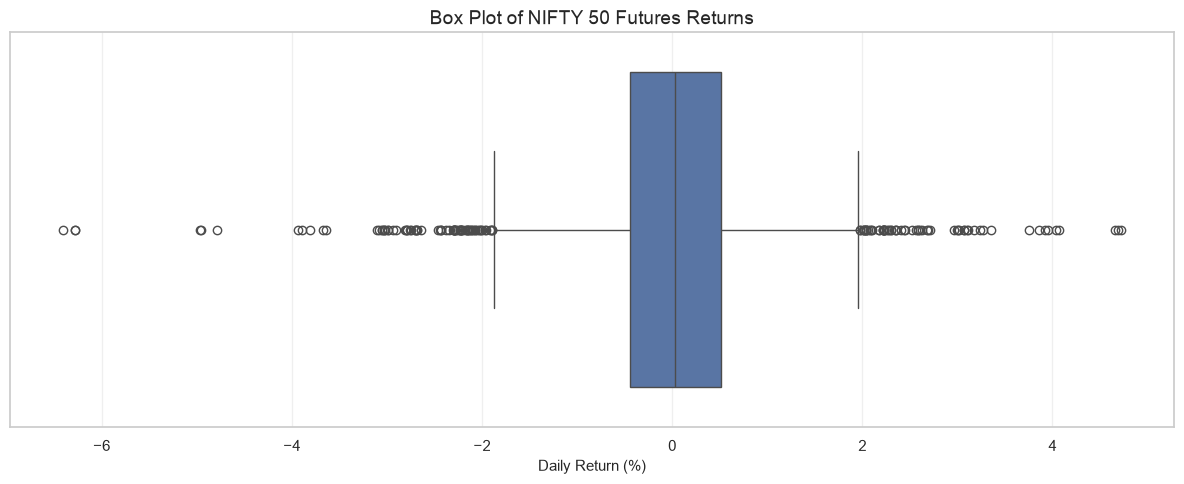

In [56]:
plt.figure(figsize=(12, 5))

sns.boxplot(x=futures_returns)

plt.title("Box Plot of NIFTY 50 Futures Returns")
plt.xlabel("Daily Return (%)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [57]:
# Calculate 20-observation rolling standard deviation within each expiry
futures_volatility["Rolling_Volatility"] = (
    futures_volatility
    .groupby("Expiry")["Daily_Return"]
    .transform(
        lambda x: x.rolling(window=20, min_periods=20).std()
    )
)

# Display observations with calculated rolling volatility
display(
    futures_volatility[
        ["Date", "Expiry", "Daily_Return", "Rolling_Volatility"]
    ].dropna().head(10)
)

,Date,Expiry,Daily_Return,Rolling_Volatility
39,2021-02-01,2021-02-25,4.68,1.48
40,2021-02-02,2021-02-25,2.40,1.56
41,2021-02-03,2021-02-25,0.85,1.57
42,2021-02-04,2021-02-25,0.50,1.57
43,2021-02-05,2021-02-25,0.24,1.57
44,2021-02-08,2021-02-25,1.31,1.57
45,2021-02-09,2021-02-25,-0.14,1.57
46,2021-02-10,2021-02-25,0.09,1.56
47,2021-02-11,2021-02-25,0.43,1.56
48,2021-02-12,2021-02-25,-0.15,1.56


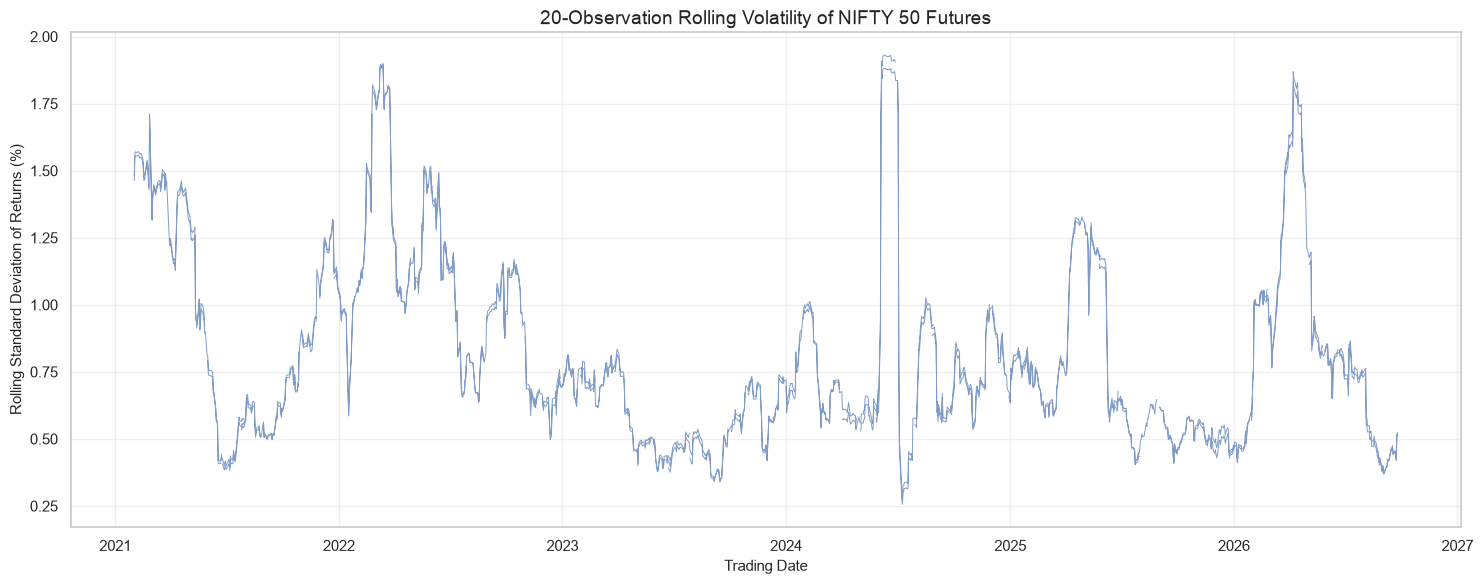

In [58]:
plt.figure(figsize=(15, 6))

plt.plot(
    futures_volatility["Date"],
    futures_volatility["Rolling_Volatility"],
    linewidth=0.7,
    alpha=0.7
)

plt.title("20-Observation Rolling Volatility of NIFTY 50 Futures")
plt.xlabel("Trading Date")
plt.ylabel("Rolling Standard Deviation of Returns (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [59]:
futures_return_statistics = pd.DataFrame({
    "Metric": [
        "Mean",
        "Median",
        "Standard Deviation",
        "Variance",
        "Minimum",
        "Maximum",
        "Skewness",
        "Kurtosis",
        "25th Percentile",
        "75th Percentile"
    ],
    "Value": [
        futures_returns.mean(),
        futures_returns.median(),
        futures_returns.std(),
        futures_returns.var(),
        futures_returns.min(),
        futures_returns.max(),
        futures_returns.skew(),
        futures_returns.kurt(),
        futures_returns.quantile(0.25),
        futures_returns.quantile(0.75)
    ]
})

display(futures_return_statistics.round(4))

,Metric,Value
0,Mean,0.01
1,Median,0.03
2,Standard Deviation,0.88
3,Variance,0.77
4,Minimum,-6.41
5,Maximum,4.72
6,Skewness,-0.33
7,Kurtosis,4.43
8,25th Percentile,-0.45
9,75th Percentile,0.52


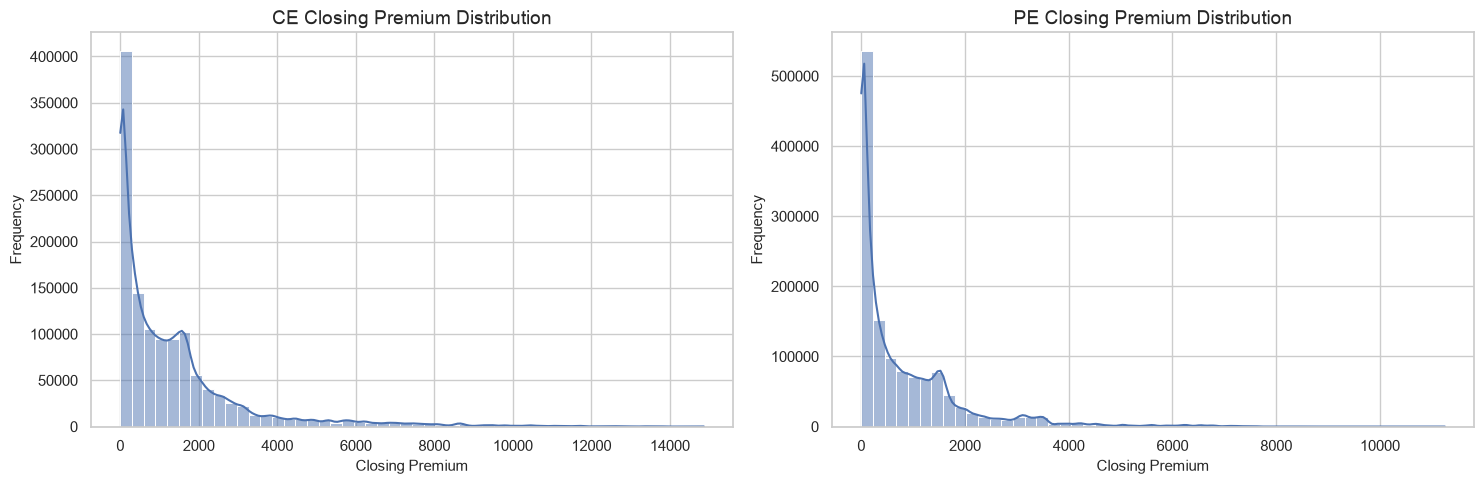

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    calls_analysis["Close"].dropna(),
    bins=50,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("CE Closing Premium Distribution")
axes[0].set_xlabel("Closing Premium")
axes[0].set_ylabel("Frequency")

sns.histplot(
    puts_analysis["Close"].dropna(),
    bins=50,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("PE Closing Premium Distribution")
axes[1].set_xlabel("Closing Premium")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [61]:
option_price_comparison = pd.DataFrame({
    "CE": calls_analysis["Close"].describe(),
    "PE": puts_analysis["Close"].describe()
})

display(option_price_comparison.round(3))

,CE,PE
count,"1,245,025.00","1,284,126.00"
mean,"1,341.41",810.59
std,"1,758.06","1,090.28"
min,0.05,0.05
25%,162.65,60.80
50%,791.90,371.10
75%,"1,729.65","1,214.25"
max,"14,862.95","11,250.00"


### Section 12 - Key Observations

This section examined the distribution and variability of NIFTY 50
derivatives prices.

The futures return distribution and rolling volatility analysis provide
insights into price variability across expiry contracts. Skewness and
kurtosis help describe the statistical characteristics of futures returns.

The CE and PE premium distributions provide an overview of option price
behaviour across different strikes and expiry dates.

These results provide a statistical foundation for the comparative
analysis in the next notebook.

## 13. Key Findings, Conclusions and Final Observations

This section summarizes the major observations obtained from the
Exploratory Data Analysis of NIFTY 50 Futures and Options data.

The analysis covers futures, call options (CE), put options (PE),
trading activity, Open Interest, strike prices, expiry dates,
price distributions, and volatility.

The objective is to consolidate the findings and identify
important patterns that can be investigated further through
comparative and statistical analysis.

In [62]:
final_dataset_summary = pd.DataFrame({
    "Dataset": ["Futures", "Call Options (CE)", "Put Options (PE)"],
    "Records": [
        len(futures_df),
        len(calls_df),
        len(puts_df)
    ],
    "Columns": [
        futures_df.shape[1],
        calls_df.shape[1],
        puts_df.shape[1]
    ],
    "Date Range": [
        f"{futures_df['Date'].min().date()} to {futures_df['Date'].max().date()}",
        f"{calls_df['Date'].min().date()} to {calls_df['Date'].max().date()}",
        f"{puts_df['Date'].min().date()} to {puts_df['Date'].max().date()}"
    ]
})

display(final_dataset_summary)

,Dataset,Records,Columns,Date Range
0,Futures,4294,15,2021-01-01 to 2026-09-25
1,Call Options (CE),1261810,18,2021-01-01 to 2026-09-25
2,Put Options (PE),1300689,18,2021-01-01 to 2026-09-25


In [63]:
final_activity_summary = pd.DataFrame({
    "Dataset": ["Futures", "Call Options (CE)", "Put Options (PE)"],
    "Total Contracts Traded": [
        futures_df["No. of contracts"].sum(),
        calls_df["No. of contracts"].sum(),
        puts_df["No. of contracts"].sum()
    ],
    "Average Closing Price": [
        futures_df["Close"].mean(),
        calls_df["Close"].mean(),
        puts_df["Close"].mean()
    ],
    "Average Open Interest": [
        futures_df["Open Int"].mean(),
        calls_df["Open Int"].mean(),
        puts_df["Open Int"].mean()
    ]
})

display(final_activity_summary.round(3))

,Dataset,Total Contracts Traded,Average Closing Price,Average Open Interest
0,Futures,"268,778,637.00","20,735.38","4,978,355.12"
1,Call Options (CE),"73,404,424,377.00","1,341.41","362,453.85"
2,Put Options (PE),"69,913,372,822.00",810.59,"326,762.38"


### Key Observations

The exploratory analysis examined the three major NIFTY 50 derivatives
datasets: futures, call options, and put options.

The following aspects were investigated:

1. **Trading Activity:** Daily, monthly, and yearly contract activity
   was examined to understand changes in market participation.

2. **Futures Market:** Futures closing prices, daily returns, and
   Open Interest were analysed to understand price behaviour.

3. **Call Options:** CE premium distributions, trading activity,
   Open Interest, strike prices, and expiry dates were explored.

4. **Put Options:** PE premium distributions, trading activity,
   Open Interest, strike prices, and expiry dates were explored.

5. **Open Interest:** Strike-wise CE and PE Open Interest were
   compared, including a single-date market snapshot and PCR.

6. **Volatility:** Futures return distributions, rolling volatility,
   skewness, and kurtosis were examined.

The numerical results and visualizations generated in the preceding
sections provide the evidence for these observations.

### Conclusion

This notebook presented an exploratory analysis of NIFTY 50 Futures
and Options market data covering the period from 1 January 2021 to
25 September 2026.

The analysis explored market activity, futures price behaviour,
call and put option premiums, Open Interest, strike prices,
expiry dates, and statistical characteristics of futures returns.

The visualizations and descriptive statistics provide an overview
of the structure and behaviour of the NIFTY derivatives market.

The analysis also highlights the importance of examining futures,
call options, and put options separately before performing
comparative analysis.

The study period ends on 25 September 2026; therefore, September
2026 represents a partial month and should not be directly compared
with complete calendar months.

The findings from this notebook will serve as the foundation for
the comparative and statistical analysis in Notebook 4.

In [64]:
# Verify all major analysis objects exist
required_objects = [
    "futures_df",
    "calls_df",
    "puts_df",
    "activity_summary_df",
    "futures_summary",
    "ce_summary",
    "pe_summary",
    "oi_by_strike",
    "snapshot_oi",
    "futures_return_statistics",
    "option_price_comparison"
]

verification_results = pd.DataFrame({
    "Object": required_objects,
    "Available": [
        name in globals()
        for name in required_objects
    ]
})

display(verification_results)

print("\nNotebook 3 Final Dataset Counts")
print("--------------------------------")
print("Futures:", len(futures_df))
print("Call Options:", len(calls_df))
print("Put Options:", len(puts_df))

print("\nTotal Records:", len(futures_df) + len(calls_df) + len(puts_df))

,Object,Available
0,futures_df,True
1,calls_df,True
2,puts_df,True
3,activity_summary_df,True
4,futures_summary,True
5,ce_summary,True
6,pe_summary,True
7,oi_by_strike,True
8,snapshot_oi,True
9,futures_return_statistics,True



Notebook 3 Final Dataset Counts
--------------------------------
Futures: 4294
Call Options: 1261810
Put Options: 1300689

Total Records: 2566793
